# Neural networks for the Bitcoin forecasts

This notebook asks one question: **do neural networks forecast Bitcoin better than the classical models of `classical-models.ipynb`?** It runs again every network of the archived notebooks, plus a few new ones, on exactly the same data, features, train / validation / test blocks and metrics as `classical-models.ipynb`. Every network is therefore compared with a classical model on the same test days.

## Main results

| Question | Best network (chosen on validation) | Its test result | Classical reference (refitted here) | Verdict |
|---|---|---|---|---|
| 24 hourly returns (the assigned task) | LSTM, Huber loss | MAE skill −0.0006 | Ridge −0.0003 | nothing beats predicting 0% |
| Direction of the next hour | LSTM classifier, every origin | AUC 0.538, top 10% right 59.4% | Gradient Boosting AUC 0.533 | tie |
| Size of each of the next 24 hours (\|r\|) | LSTM + hour features, every origin | R² 0.132 | Gradient Boosting refitted every month R² 0.148 (fitted once 0.130) | **network worse than the refitted GB (−0.016, reliable)**; tie with GB fitted once |
| Next-day volatility | ensemble GB + MLP | R² 0.518 (MLP alone 0.507) | Gradient Boosting R² 0.505 | **ensemble better (+0.013, reliable)**; the MLP alone ties |
| Next-day move size (course pipeline) | Keras MLP | R² 0.399 | Linear Regression R² 0.514 | network worse |

**In short:** a network alone never beats the best classical model on this data. For the size of the hourly moves the best classical model is Gradient Boosting refitted every month (0.148): the network chosen on validation, an LSTM that knows the clock and the releases of the hours it predicts, only ties Gradient Boosting fitted once. Averaging the networks with Gradient Boosting reaches 0.157 on test, but validation did not pick that average. For next-day volatility the average of Gradient Boosting and an MLP is reliably better than Gradient Boosting alone. Section 9 gives the conclusions in full.

## How to read this notebook

Sections 1–2 build the data and the tools; to go straight to the results, skip to section 3. Sections 3–7 each answer one question, always in the same order: **the question and what there is to beat → the models → code and tables → "What we see"**, whose first line gives the answer. Section 8 checks which differences are reliable and section 9 sums up.

| Section | Question | Networks |
|---|---|---|
| 1 | Data, features and the three blocks | — |
| 2 | Metrics, baselines and the training loop | — |
| 3 | 24 hourly returns (the assigned task) | MLP, RNN, LSTM |
| 4 | Direction of the next hour | MLP and LSTM classifiers |
| 5 | Size of each of the next 24 hours (**main experiment**) | MLP, LSTM, ensembles with Gradient Boosting |
| 6 | Next-day volatility | MLP, ensemble with Gradient Boosting |
| 7 | Next-day move size, course pipeline | Keras MLP |
| 8 | How sure are we? Bootstrap confidence intervals | — |
| 9 | Conclusions | — |

## Key terms

| Term | Meaning |
|---|---|
| **forecast origin** | the hour at which a forecast is made: every hour with 30 days of history before it and 24 hours after it |
| **train / validation / test** | three blocks of time (section 1.2). Every choice is made on train and validation; the test block is used once, at the end |
| **every 6th origin / every origin** | train and validation normally keep one origin in six, as in the classical notebook. "Every origin" trains on all of them: 6× more rows, but neighbouring rows overlap |
| **wide / long format** | wide: one row per origin; long: one row per origin and predicted hour (section 1.3) |
| **zero forecast** | predicting 0% change for every hour: the baseline to beat for returns |
| **MAE skill** | 1 − MAE of the model / MAE of the zero forecast. Above 0 means better than the zero forecast |
| **R²_oos** | R² measured against the zero forecast instead of the mean (used for returns) |
| **IC** | correlation between the forecasts and what happened |
| **R²** | share of the variation explained (used for the size of the moves and for volatility) |
| **AUC** | quality of a direction forecast: 0.5 is a coin flip, 1 is perfect |
| **top 10% accuracy** | how often the 10% most confident direction calls are right |
| **GB** | Gradient Boosting, the best classical model on most targets |
| **monthly refit** | the model is refitted at the start of every month on everything known by then, with more weight on recent months (section 5.1) |
| **ensemble** | the plain average of the forecasts of several models |
| **seeds** | every final network is trained `N_SEEDS` = 3 times from different random starts. Tables show the score of their average forecast and the spread of the single seeds |
| **reliable** | the 95% bootstrap interval of a difference does not include 0 (section 8) |

## Rules

These are the rules of `classical-models.ipynb`:

- The blocks are cut by the date of the predicted hours, with a 192-hour gap (purge) before each border, so that no input or target hour crosses into the next block.
- Every choice (architecture, regularization, number of epochs) is made on train and validation only. The chosen network is refitted on train + validation **for the number of epochs chosen on validation** and evaluated **once** on the test block. The only exception is the Keras MLP of section 7, kept as in `course-methods.ipynb`.
- Early stopping watches the **validation block**, which comes later in time, never a random hold-out: with overlapping origins, a random hold-out has near-identical neighbours in the training rows.
- Network training is random (initial weights, order of the batches), so every final network except the Keras MLP is trained with several seeds.
- The classical reference models are refitted here with the grids of `classical-models.ipynb`, so the differences can be tested on the same test days (section 8).

## Sources

The networks come from five archived notebooks:

| Archived notebook | Author | What is taken |
|---|---|---|
| `models-and-hyperparameters-ver1.ipynb` (early draft) | Alberto | the first scikit-learn `MLPRegressor`; versions 1–2 repeated it |
| `bitcoin-models-new-data.ipynb` (version 1) | Alberto | `MLPRegressor` on the 42 scale-free features for the 24 hourly returns |
| `bitcoin-models-2018-2026.ipynb` (version 2) | Alberto | the same MLP with the extended `alpha` grid |
| `model_test.ipynb` | Adrián P. | RNN and LSTM in PyTorch on the 168-hour sequence, and their training loop with early stopping |
| `course-methods.ipynb` | Filip | the Keras MLP of Lab VI for the next day's move size |

The notebook also takes up tasks 6 and 7 of the README to-do list: window-normalized inputs for the recurrent networks, a robust loss (Huber), and the targets where the classical models found signal. It leaves out the questions where the classical models found nothing for a network to improve on, or already solve them: the next-day return (R²_oos −0.001, IC 0.05) and direction (AUC 0.509), the 80% ranges (80.0% coverage with rolling conformal calibration) and the economic test (`classical-models.ipynb`, sections 8.2, 8.3, 7 and 10).

Quotes from the archived notebooks are marked with their source in *italics*. Their numbers come from other data (the old `.npz` windows) and other splits, so they differ from those of this run. Nothing here reads the old `.npz` windows: the data is `data/btc_hourly.csv.gz` from 1 Jan 2020 (`DATA_START`, as in every notebook of the project), 59,331 consecutive hours, 1 Jan 2020 → 8 Oct 2026.

**Run time:** 41.2 minutes on the last run, with PyTorch on a CUDA GPU (RTX 5060 Laptop, PyTorch built for CUDA 13.0). The largest part is the monthly refits of Gradient Boosting (section 5.1, 21 minutes on the CPU: scikit-learn bins weighted samples slowly). On the GPU the LSTM on every origin takes about a minute; on a CPU only, the previous version of this notebook took 133 minutes, most of it LSTM training. The MLPs of scikit-learn and Keras always run on the CPU.

## 1. Settings, data, features and blocks

*Setup: to see the results, skip to section 3.*

Run the notebook from the repo root, so that `data/` and `utils/` are found. Features, targets, metrics and statistical tests come from `utils/hourly.py`. Sections 1.1–1.3 repeat sections 1.1–1.3 of `classical-models.ipynb`, so the forecast origins and the blocks are identical; section 1.4 builds the input of the recurrent networks.

The networks are written in PyTorch (as in `model_test.ipynb`) or taken from scikit-learn (`MLPRegressor`, `MLPClassifier`, as in versions 1–2). The MLP of section 7 keeps its original Keras code.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # conda's MKL numpy and pip's torch each ship libiomp5md.dll (model_test.ipynb)
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (balanced_accuracy_score, mean_absolute_error, mean_squared_error, r2_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, ParameterGrid, TimeSeriesSplit
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U
from utils.config import DATA_START, TEST_START, VAL_START
from utils.features import (NEXT_DAY_FEATURES, ORIGIN_FEATURES, TARGET_HOUR_FEATURES, load_releases,
                            next_day_release_features, origin_features, recent_hour_profile, target_hour_features)

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
WINDOW = pd.Timedelta(hours=192)            # purge before each border (168 input + 24 target hours, versions 2-3)
STRIDE = 6                                  # train and validation keep every 6th forecast origin
SEQ_HOURS = 168                             # input length of the recurrent models (one week, as in model_test.ipynb)
N_SEEDS = 3                                 # every final network is trained with this many seeds
N_JOBS = 4                                  # parallel grid searches (section 6): each worker process reserves ~1 GB
RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T_START = time.time()
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
print(f"PyTorch {torch.__version__}, device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

# Colours and axes style shared by the plots (as in classical-models.ipynb)
BLUE, ORANGE, AQUA, GREY, INK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e", "#6250d6"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

PyTorch 2.14.1+cu130, device: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


### 1.1 Data, forecast origins and targets

- **Period.** The data starts on 1 January 2020 (`DATA_START` of `utils/config.py`), as in every notebook of the project. The daily rhythm of volatility changed over the years (`data-analysis.ipynb`): the 14 UTC peak grew from 1.17× the average hour in 2020 to 1.70× in 2024–25, and weekends fell from 0.8× to 0.6×. Older hours describe a market that no longer exists.
- `Return` is the hourly return, in **percent**.
- Every hour with 30 days of history behind it and 24 hours after it is a **forecast origin**. `y_all[i, h]` is the return of hour *h* + 1 after origin *i*.
- The inputs are the 42 scale-free **base** features of versions 1–2.
- The 30-day and range-based features of version 3 are computed but not used. They only make the first origin the same as in `classical-models.ipynb`.
- The new features of `data-analysis.ipynb` (section 9.2) come from `utils/features.py`. **B4** describes the last day at the origin: `rv_ratio_1d_30d` (last day's average |r| against the last month's), `jump_ratio_1d` (largest move of the last day against the monthly average) and `filled_minutes_1d` (minutes without trades in the last day). The releases of the next 24 hours (`next_day_cpi`, `next_day_payrolls`, `next_day_fomc`, `next_day_release`) are used for the next-day volatility (section 6). The features of the predicted hour are in section 1.3. The VIX and the hours to / since a release had no signal in `data-analysis.ipynb` and are not used.

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True).loc[DATA_START:].copy()
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"
ret, absr = hourly["Return"].values, hourly["Return"].abs().values

F_base, F_b1, F_b2 = U.base_features(hourly), U.long_lookback_features(hourly), U.range_vol_features(hourly)
FEAT = pd.concat([F_base, F_b1, F_b2], axis=1)
BASE = list(F_base.columns)

# forecast origins: every hour with all features defined (30 days of history) and 24 hours after it
ok = np.isfinite(FEAT.values).all(axis=1)
first = int(np.argmax(ok))
assert ok[first:].all(), "missing feature values inside the series"
pos_all = np.arange(first, len(hourly) - U.H_AHEAD)
origins = hourly.index[pos_all]
y_all = np.stack([ret[pos_all + k] for k in range(1, U.H_AHEAD + 1)], axis=1)     # next 24 returns, %

# features of data-analysis.ipynb, section 9.2 (utils/features.py), known at the origin: B4 and the releases of the next 24 h
releases = load_releases()
B4, B5 = list(ORIGIN_FEATURES), list(TARGET_HOUR_FEATURES)
FEAT = FEAT.join(origin_features(hourly)).join(next_day_release_features(hourly, releases))
assert np.isfinite(FEAT[B4 + NEXT_DAY_FEATURES].values[pos_all]).all()

print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
print(f"{len(origins):,} forecast origins   {origins[0]} -> {origins[-1]}")
print(f"base features: {len(BASE)}, B4 (origin): {len(B4)}, B5 (predicted hour): {len(B5)}")

59,331 hours   2020-01-01 00:00:00 -> 2026-10-08 02:00:00
58,588 forecast origins   2020-01-30 23:00:00 -> 2026-10-07 02:00:00
base features: 42, B4 (origin): 3, B5 (predicted hour): 5


### 1.2 The three blocks

As in `classical-models.ipynb` (section 1.2):

| Block | Predicted hours | Origins kept |
|---|---|---|
| train | Jan 2020 → Dec 2022 | every 6th (`STRIDE = 6`) |
| validation | Jan 2023 → Jun 2024 | every 6th |
| test | Jul 2024 → Oct 2026 | every origin |

- **Test days.** Every 24th test origin is a forecast made at **23:00 for the next calendar day**. These `test_days` do not overlap, so they are used for the daily targets and for the significance tests.
- **Every origin.** Networks usually need more examples than tree models, so sections 4 and 5 also train on every origin of the train block (`train1`) and refit on every origin of train + validation (`tv1`). That gives 6× more rows, although neighbouring origins share most of their input and, for the 24-hour targets, 23 of their 24 target hours. Validation always keeps every 6th origin, as for the classical models.

In [3]:
start_hour = origins + pd.Timedelta(hours=1)              # first predicted hour
day_end = origins + pd.Timedelta(hours=U.H_AHEAD)         # last predicted hour
in_train = np.flatnonzero(day_end < VAL_START - WINDOW)
in_val = np.flatnonzero((start_hour >= VAL_START) & (day_end < TEST_START - WINDOW))
blk = {
    "train": in_train[::STRIDE],
    "val": in_val[::STRIDE],
    "test": np.flatnonzero(start_hour >= TEST_START),
}
blk["tv"] = np.r_[blk["train"], blk["val"]]                # train + validation (refit of the chosen models)
blk["train1"], blk["tv1"] = in_train, np.r_[in_train, in_val]   # every origin (sections 4-5)
P = {k: pos_all[v] for k, v in blk.items()}               # positions in the hourly series
Y = {k: y_all[v] for k, v in blk.items()}                 # next 24 returns, %
D = {k: origins[v] for k, v in blk.items()}               # origin timestamps
n_tr, n_va = len(P["train"]), len(P["val"])
test_days = np.arange(0, len(P["test"]), 24)              # one origin per day (23:00) -> independent days
assert (D["test"][test_days].hour == 23).all()
ND = len(test_days)

display(pd.DataFrame({
    "origins": {k: len(P[k]) for k in P},
    "first origin": {k: D[k][0] for k in P},
    "last origin": {k: D[k][-1] for k in P},
    "avg |hourly move| %": {k: np.abs(Y[k]).mean() for k in P},
    "up days": {k: (U.compound(Y[k]) > 0).mean() for k in P},
}))
print(f"independent test days: {ND}")

,origins,first origin,last origin,avg |hourly move| %,up days
train,4229,2020-01-30 23:00:00,2022-12-22 23:00:00,0.502392,0.524474
val,2153,2022-12-31 23:00:00,2024-06-21 23:00:00,0.301283,0.530887
test,19876,2024-06-30 23:00:00,2026-10-07 02:00:00,0.319275,0.517408
tv,6382,2020-01-30 23:00:00,2024-06-21 23:00:00,0.434547,0.526637
train1,25369,2020-01-30 23:00:00,2022-12-22 23:00:00,0.502450,0.521069
tv1,38282,2020-01-30 23:00:00,2024-06-21 23:00:00,0.434625,0.524894


independent test days: 829


### 1.3 Wide and long format

- **Wide** (versions 1–2): one row per origin with its features; the target is the 24 returns, or one daily value.
- **Long** (version 3): every origin becomes 24 rows, one per predicted hour, with extra columns that say *which* hour is predicted. See `classical-models.ipynb`, section 1.3.

| Per-hour column | Meaning |
|---|---|
| `h_ahead` | 1 … 24: how many hours after the origin |
| `tgt_hour_sin/cos`, `tgt_dow_sin/cos` | hour of day and weekday of the **predicted** hour |
| **B3:** `tgt_weekend` | 1 if the predicted hour is on Saturday/Sunday |
| **B3:** `tgt_hour_profile` | average size of moves at that hour of day in the train block, divided by the overall average |
| **B3:** `absret_same_hour_1d`, `absret_same_hour_7d` | size of the move at the same hour yesterday and one week ago |
| **B3:** `ret_same_hour_1d` | return at the same hour yesterday |
| **B5:** `tgt_cpi`, `tgt_payrolls`, `tgt_fomc` | 1 if a scheduled CPI, Payrolls or FOMC release falls in the predicted hour (about 3× the move of the other hours, `data-analysis.ipynb`, section 9.2) |
| **B5:** `tgt_after_fomc`, `tgt_us_session` | 1 in the two hours after an FOMC statement; 1 from 13 to 16 UTC |
| `tgt_hour_profile_recent` | the same profile as `tgt_hour_profile`, but from the 90 days before the origin, so it follows the changing daily rhythm |

B4 (section 1.1) is a feature of the origin, repeated on its 24 rows. Every column only uses what is known at the origin: the release calendar is fixed in advance, and unscheduled events (the two emergency FOMC cuts of March 2020) are left out. Section 5.1 chooses among these groups.

`rule_abs` is the strongest simple rule for the size of a move: **last week's average |r| × the hour-of-day profile** (version 3, section 5).

In [4]:
H_BASE = ["h_ahead", "tgt_hour_sin", "tgt_hour_cos", "tgt_dow_sin", "tgt_dow_cos"]
B3 = ["tgt_weekend", "tgt_hour_profile", "absret_same_hour_1d", "absret_same_hour_7d", "ret_same_hour_1d"]
RECENT = ["tgt_hour_profile_recent"]
tr_abs = hourly["Return"].abs().loc[D["train"][0]: D["train"][-1] + pd.Timedelta(hours=U.H_AHEAD)]
HOUR_PROFILE = (tr_abs.groupby(tr_abs.index.hour).mean() / tr_abs.mean()).values
week_abs = pd.Series(absr).rolling(168).mean().values               # last week's average |r| at each hour
TGT = target_hour_features(hourly.index, releases)[B5].values       # B5 of every hour (known in advance)
RECENT_PROFILE = recent_hour_profile(hourly)                        # row t: hour-of-day profile of the 90 days up to t

# candidate inputs of the long format, (origin columns, per-hour columns): classical-models.ipynb, section 6.4
FSETS = {"base": (BASE, H_BASE), "base + B3": (BASE, H_BASE + B3), "base + B3 + B4": (BASE + B4, H_BASE + B3),
         "base + B3 + B5": (BASE, H_BASE + B3 + B5), "base + B3 + B4 + B5": (BASE + B4, H_BASE + B3 + B5),
         "base + B3 + B4 + B5 + recent profile": (BASE + B4, H_BASE + B3 + B5 + RECENT)}


def Xw(block, cols):
    # Wide format: one row per origin
    return FEAT[cols].values[P[block]]


def Xl(block, cols, hcols=H_BASE):
    # Long format: 24 rows per origin (origin-major order); cols = origin features, hcols = per-hour features
    p = P[block]
    base = np.repeat(FEAT[cols].values[p], 24, axis=0)
    h_ = np.tile(np.arange(1, 25), len(p))
    tp = np.repeat(p, 24) + h_                                       # position of the predicted hour
    t = hourly.index[tp]
    extra = {
        "h_ahead": h_,
        "tgt_hour_sin": np.sin(2 * np.pi * t.hour / 24), "tgt_hour_cos": np.cos(2 * np.pi * t.hour / 24),
        "tgt_dow_sin": np.sin(2 * np.pi * t.dayofweek / 7), "tgt_dow_cos": np.cos(2 * np.pi * t.dayofweek / 7),
        "tgt_weekend": (t.dayofweek >= 5).astype(float),
        "tgt_hour_profile": HOUR_PROFILE[t.hour],
        "absret_same_hour_1d": absr[tp - 24], "absret_same_hour_7d": absr[tp - 168],
        "ret_same_hour_1d": ret[tp - 24],
        "tgt_hour_profile_recent": RECENT_PROFILE[tp - h_, t.hour],   # profile known at the origin, for the predicted hour
        **{c: TGT[tp, j] for j, c in enumerate(B5)},
    }
    return np.hstack([base, np.column_stack([extra[c] for c in hcols])])


def yl(block, kind="abs"):
    v = Y[block].reshape(-1)
    return np.abs(v) if kind == "abs" else v


def rule_abs(block):
    # Baseline: last week's average |r| x hour-of-day profile of the predicted hour
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return week_abs[p] * HOUR_PROFILE[hourly.index[p + h_].hour]

### 1.4 Sequence input for the recurrent networks

The RNN and the LSTM read the **168 hours (one week)** before each origin. In `model_test.ipynb` each hour was described by its Open, High, Low, Close, Volume and Return, scaled with one global scaler or left raw. Neither is scale-free: 72% of the test hours trade above the highest train price (`data-analysis.ipynb`, section 2), so the test inputs lie outside anything the network saw in training.

Following task 6 of the README ("normalize each window by itself"), every hour of the window is described here by 10 channels that mean the same in 2020 and in 2026:

| Channel | Meaning |
|---|---|
| `ret`, `abs_ret` | return of the hour and its size (%) |
| `hl_range` | (High − Low) / Close of the hour (%) |
| `price_vs_last` | log price relative to the last close of the window (%): the price path of the week, ending at 0 |
| `volume_vs_window` | log volume relative to the window's average log volume |
| `filled_minutes` | minutes of the hour without trades, filled in by `hourly-base-data.ipynb` (0 for most hours) |
| `hour_sin`, `hour_cos`, `dow_sin`, `dow_cos` | hour of day and weekday of the hour |

Each channel is then standardized with the mean and standard deviation of the train block and clipped at ±10 standard deviations, so a few extreme hours cannot dominate a batch.

In [5]:
hl_pct = ((hourly["High"] - hourly["Low"]) / hourly["Close"]).values * U.PCT
log_close = np.log(hourly["Close"].values)
log_vol = np.log1p(hourly["Volume"].clip(lower=0).values)
filled = hourly["filled_minutes"].values.astype(float)
calendar = np.column_stack([np.sin(2 * np.pi * hourly.index.hour / 24), np.cos(2 * np.pi * hourly.index.hour / 24),
                            np.sin(2 * np.pi * hourly.index.dayofweek / 7), np.cos(2 * np.pi * hourly.index.dayofweek / 7)])
CHANNELS = ["ret", "abs_ret", "hl_range", "price_vs_last", "volume_vs_window", "filled_minutes",
            "hour_sin", "hour_cos", "dow_sin", "dow_cos"]


def raw_seq(pos):
    # The SEQ_HOURS hours up to each origin, window-normalized channels: array (origins, SEQ_HOURS, channels)
    idx = pos[:, None] + np.arange(-SEQ_HOURS + 1, 1)
    x = np.empty(idx.shape + (len(CHANNELS),), np.float32)
    x[..., 0], x[..., 1], x[..., 2] = ret[idx], absr[idx], hl_pct[idx]
    x[..., 3] = (log_close[idx] - log_close[pos][:, None]) * U.PCT
    x[..., 4] = log_vol[idx] - log_vol[idx].mean(axis=1, keepdims=True)
    x[..., 5] = filled[idx]
    x[..., 6:] = calendar[idx]
    return x


_tr = raw_seq(P["train"]).reshape(-1, len(CHANNELS))
SEQ_MU, SEQ_SD = _tr.mean(axis=0), _tr.std(axis=0)
del _tr


def seq(block):
    return np.clip((raw_seq(P[block]) - SEQ_MU) / SEQ_SD, -10, 10).astype(np.float32)


S = {k: seq(k) for k in ("train", "val", "test", "tv")}
print(f"sequence input: {SEQ_HOURS} hours x {len(CHANNELS)} channels | origins: train {len(S['train']):,}, "
      f"validation {len(S['val']):,}, test {len(S['test']):,}")
display(pd.DataFrame({"train mean": SEQ_MU, "train std": SEQ_SD,
                      "test: share clipped": (np.abs(S["test"]) >= 10).mean(axis=(0, 1))}, index=CHANNELS).round(4))

sequence input: 168 hours x 10 channels | origins: train 4,229, validation 2,153, test 19,876


,train mean,train std,test: share clipped
ret,0.0060,0.8294,0.0000
abs_ret,0.5030,0.6596,0.0000
hl_range,1.0821,0.9950,0.0000
price_vs_last,-0.1926,7.1778,0.0000
volume_vs_window,-0.0000,0.8288,0.0000
filled_minutes,0.9741,2.6244,0.0016
hour_sin,-0.0000,0.7071,0.0000
hour_cos,-0.0000,0.7071,0.0000
dow_sin,0.0000,0.7070,0.0000
dow_cos,-0.0000,0.7072,0.0000


## 2. Metrics, baselines and the training loop

*Setup: to see the results, skip to section 3.*

The metrics and baselines are those of `classical-models.ipynb` (section 2), explained under *Key terms* at the top. The helpers below are copied from its section 1.4.

**Training loop.** `train_net` keeps the loop of `model_test.ipynb`: mini-batches, AdamW, gradient norm clipped at 1, early stopping on the validation block with a patience, and the best weights restored at the end. It adds three things:

1. other losses: Huber and binary cross-entropy;
2. a run **without** validation for a fixed number of epochs, used for the final refit on train + validation with the number of epochs that early stopping chose. The number of epochs is treated as a hyperparameter, like the number of trees;
3. targets divided by their train standard deviation (as in `model_test.ipynb`), and predictions scaled back;
4. optional weights of the training rows, as `sample_weight` in scikit-learn: the monthly refits of section 5.4 give recent months more weight.

**Tuning.** `nn_grid` tries each setting of a small grid (fit on train, early stopping on validation) and keeps the best by its validation score. `refit_net` refits the chosen setting on train + validation, once per seed.

| Network | Layers | Source |
|---|---|---|
| `MLPNet` | fully connected layers with ReLU and dropout, linear output | the MLP of versions 1–2, in PyTorch |
| `RecurrentNet` | stacked `nn.RNN` or `nn.LSTM`, then dropout and a linear head on the last hidden state | `RecurrentForecaster` of `model_test.ipynb` |
| `FutureHeadLSTM` | the same LSTM encoder; a small head shared by the 24 predicted hours reads the last hidden state together with the features of each predicted hour | new (section 5.3) |

In [6]:
def safe_corr(a, b):
    return U.safe_corr(a, b)


def metrics(y_true, y_pred):
    # Return metrics of versions 1-2, on returns in %
    nz = y_true != 0
    mae, mae0 = mean_absolute_error(y_true, y_pred), np.abs(y_true).mean()
    d_true, d_pred = U.compound(y_true), U.compound(y_pred)
    return {"MAE": mae, "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE_skill": 1 - mae / mae0,
            "R2_oos": U.r2_oos(y_true, y_pred), "IC": safe_corr(y_pred, y_true),
            "HourDirAcc": ((y_pred[nz] > 0) == (y_true[nz] > 0)).mean(),
            "DayDirAcc": ((d_pred > 0) == (d_true > 0)).mean()}


INT_KEYS = ("max_depth", "min_samples_leaf", "max_iter", "n_neighbors", "n_estimators")


def as_int(p):
    return {k: (int(v) if k in INT_KEYS and v is not None and not pd.isna(v) else
                None if k == "max_depth" and pd.isna(v) else
                v.item() if isinstance(v, np.generic) else v) for k, v in p.items()}


def tune(make_model, grid, Xa, ya, Xb, yb, score_fn, show=True):
    # Fit each setting on (Xa, ya), score on (Xb, yb). score_fn(y, pred) -> dict with key 'score'
    rows, grid = [], list(ParameterGrid(grid))
    for p in grid:
        t0 = time.time()
        s = score_fn(yb, make_model(**p).fit(Xa, ya).predict(Xb))
        rows.append({**p, **s, "seconds": round(time.time() - t0, 1)})
    t = pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)
    if show:
        display(t.round(4))
    return t, as_int(t.iloc[0][list(grid[0])].to_dict())


WF = list(TimeSeriesSplit(n_splits=4, gap=int(np.ceil(WINDOW / pd.Timedelta(hours=1) / STRIDE))).split(np.arange(n_tr + n_va)))


def rows24(idx):
    return (np.asarray(idx)[:, None] * 24 + np.arange(24)).ravel()


def seed_spread(y, preds, score):
    # Score of each seed's forecast: "mean ± std" over seeds
    s = [score(y, p) for p in preds]
    return f"{np.mean(s):.4f} ± {np.std(s, ddof=1):.4f}" if len(s) > 1 else f"{s[0]:.4f}"


vol_scores = lambda y, p: {"score": U.r2(y, p), "MAE": mean_absolute_error(y, p), "corr": safe_corr(p, y)}
make_gb = lambda **p: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
SUMMARY = []


# ---------------------------------------------------------------- PyTorch networks and training loop
class MLPNet(nn.Module):
    # Fully connected network: (Linear -> ReLU -> Dropout) per hidden layer, then a linear output
    def __init__(self, n_in, hidden=(64, 32), n_out=1, dropout=0.0):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        self.net = nn.Sequential(*layers, nn.Linear(d, n_out))
        self.n_out = n_out

    def forward(self, x):
        out = self.net(x)
        return out[:, 0] if self.n_out == 1 else out


class FutureHeadLSTM(nn.Module):
    # An LSTM encoder reads the sequence; one small head, shared by the 24 predicted hours, maps
    # [last hidden state, features of predicted hour h] to the forecast of hour h. The input row is the flattened
    # sequence (SEQ_HOURS x n_channels) followed by the flattened per-hour features (24 x n_future).
    def __init__(self, n_channels, n_future, hidden_size=64, num_layers=2, dropout=0.2, head=64):
        super().__init__()
        self.n_ch, self.n_fut, self.n_seq = n_channels, n_future, SEQ_HOURS * n_channels
        self.rnn = nn.LSTM(n_channels, hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden_size + n_future, head), nn.ReLU(), nn.Dropout(dropout), nn.Linear(head, 1))

    def forward(self, x):
        s = x[:, :self.n_seq].reshape(len(x), SEQ_HOURS, self.n_ch)
        f = x[:, self.n_seq:].reshape(len(x), U.H_AHEAD, self.n_fut)
        out, _ = self.rnn(s)
        h = out[:, -1].unsqueeze(1).expand(-1, U.H_AHEAD, -1)        # the same state for each predicted hour
        return self.head(torch.cat([h, f], dim=2))[..., 0]


class RecurrentNet(nn.Module):
    # model_test.ipynb: a stacked RNN/LSTM reads the sequence, a linear head maps the last hidden state to the outputs
    def __init__(self, cell, n_features, hidden_size=64, num_layers=2, dropout=0.2, n_out=24):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM}[cell]
        self.rnn = rnn_cls(n_features, hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_size, n_out))
        self.n_out = n_out

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.head(out[:, -1])
        return out[:, 0] if self.n_out == 1 else out


LOSSES = {"mse": nn.MSELoss, "huber": nn.HuberLoss, "bce": nn.BCEWithLogitsLoss}


def to_t(a):
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))


def free_gpu():
    # On Windows the memory PyTorch keeps cached on the GPU is also reserved in the process (commit charge),
    # so it is handed back after every fit and prediction
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


@torch.no_grad()
def predict_net(net, X, batch=1024):
    # batches of 1,024: with 4,096 sequences of 168 hours the LSTM reserves ~8 GB of GPU memory
    net.eval()
    out = np.concatenate([net(to_t(X[i:i + batch]).to(DEVICE)).cpu().numpy() for i in range(0, len(X), batch)])
    free_gpu()
    return out


def train_net(make_net, X, y, X_val=None, y_val=None, epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512,
              loss="mse", clip=1.0, seed=RANDOM_STATE, w=None):
    # Mini-batch training (model_test.ipynb). With (X_val, y_val): early stopping on the validation loss and the best
    # weights restored. Without: exactly `epochs` epochs (the refit on train + validation). w: weights of the
    # training rows, as sample_weight in scikit-learn (monthly refits, section 5.4).
    torch.manual_seed(seed)
    net = make_net().to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn, row_loss = LOSSES[loss](), LOSSES[loss](reduction="none")
    Xt, yt = to_t(X).to(DEVICE), to_t(y).to(DEVICE)
    wt = None if w is None else to_t(w).to(DEVICE)
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    hist, best, best_state, bad = {"train": [], "val": []}, np.inf, None, 0
    net.best_epoch = epochs
    for epoch in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(len(Xt), device=DEVICE, generator=gen)
        total = 0.0
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]
            opt.zero_grad()
            if wt is None:
                batch_loss = loss_fn(net(Xt[b]), yt[b])
            else:
                lb = row_loss(net(Xt[b]), yt[b])
                wb = wt[b].reshape((-1,) + (1,) * (lb.dim() - 1))
                batch_loss = (lb * wb).sum() / (wb.sum() * lb[0].numel())
            batch_loss.backward()
            if clip:
                nn.utils.clip_grad_norm_(net.parameters(), clip)
            opt.step()
            total += batch_loss.item() * len(b)
        hist["train"].append(total / len(Xt))
        if X_val is None:
            continue
        hist["val"].append(loss_fn(to_t(predict_net(net, X_val)), to_t(y_val)).item())
        if hist["val"][-1] < best:
            best, bad, net.best_epoch = hist["val"][-1], 0, epoch
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    del Xt, yt, wt
    free_gpu()
    return net, hist


def early_stop_fit(make_net, Xa, ya, Xv, yv, scale=1.0, **kw):
    # Fit on train with early stopping on validation -> (validation forecast, chosen number of epochs, history)
    net, hist = train_net(make_net, Xa, ya / scale, Xv, yv / scale, **kw)
    return predict_net(net, Xv) * scale, net.best_epoch, hist


def refit_net(make_net, X, y, X_test, n_epochs, scale=1.0, seeds=N_SEEDS, seed0=RANDOM_STATE, **kw):
    # Refit on train + validation for the chosen number of epochs, once per seed -> one test forecast per seed
    kw = {k: v for k, v in kw.items() if k not in ("epochs", "patience")}
    return [predict_net(train_net(make_net, X, y / scale, epochs=n_epochs, seed=seed0 + s, **kw)[0], X_test) * scale
            for s in range(seeds)]


def nn_grid(spec, grid, Xa, ya, Xv, yv, score_fn, scale=1.0, **kw):
    # spec(**setting) -> (network factory, training options). Each setting: fit on train, early stopping on
    # validation, scored by score_fn(y, pred)["score"]. Returns the table (best first) and the best run.
    rows, runs = [], []
    for p in ParameterGrid(grid):
        t0 = time.time()
        make_net, tkw = spec(**p)
        pv, ep, hist = early_stop_fit(make_net, Xa, ya, Xv, yv, scale, **{**kw, **tkw})
        rows.append({**p, **score_fn(yv, pv), "epochs": ep, "seconds": round(time.time() - t0, 1)})
        runs.append({"params": p, "val": pv, "epochs": ep, "hist": hist})
    t = pd.DataFrame(rows)
    best = runs[int(t["score"].idxmax())]
    display(t.sort_values("score", ascending=False).round(4))
    return t, best


def refit_best(spec, best, X, y, X_test, scale=1.0, **kw):
    make_net, tkw = spec(**best["params"])
    return refit_net(make_net, X, y, X_test, best["epochs"], scale, **{**kw, **tkw})

## 3. The assigned task: the 24 hourly returns

**Question.** Can a network forecast the returns of the next 24 hours better than predicting 0%?

**To beat.** In `classical-models.ipynb` (section 3.4) every tuned model lands within 0.0005 of the zero forecast (MAE skill −0.0004 to −0.0002), and no daily direction is significant.

**Networks.**

- 3.1: the scikit-learn MLP of versions 1–2;
- 3.2: the RNN and LSTM of `model_test.ipynb`, with the two fixes the README proposes (window-normalized inputs and the Huber loss).

All of them are in wide format: one network gives the 24 returns of the next day. As in `classical-models.ipynb` (section 3), the chosen setting is refitted on train + validation and evaluated once on every test origin (`final_report`). The daily direction accuracy, its binomial p-value and the balanced accuracy use the independent test days. The cell below refits the baselines and the classical Ridge for the comparison.

In [7]:
Ftr, Fva, Fte = Xw("train", BASE), Xw("val", BASE), Xw("test", BASE)
Ytr, Yva, Yte = Y["train"], Y["val"], Y["test"]
Ftv, Ytv = Xw("tv", BASE), Y["tv"]
VAL_PARTS = np.array_split(np.arange(n_va), 3)                 # 3 consecutive half-years of the validation block
results, test_preds = [], {}


def val_tune(make_model, grid, show=True):
    # Train on the train block, score on the validation block: one row per setting, best first
    rows = []
    for params in ParameterGrid(grid):
        t0 = time.time()
        m = make_model(**params).fit(Ftr, Ytr)
        pred_va = m.predict(Fva)
        va = metrics(Yva, pred_va)
        parts = [metrics(Yva[p], pred_va[p])["MAE_skill"] for p in VAL_PARTS]
        rows.append({**params, "train_skill": metrics(Ytr, m.predict(Ftr))["MAE_skill"],
                     "val_skill": va["MAE_skill"], "val_skill_std": np.std(parts, ddof=1),
                     "val_MAE": va["MAE"], "val_IC": va["IC"], "val_DayDirAcc": va["DayDirAcc"],
                     "seconds": round(time.time() - t0, 1)})
    out = pd.DataFrame(rows).sort_values("val_skill", ascending=False).reset_index(drop=True)
    if show:
        display(out.round(4))
    return out


def best_params(table, keys):
    return as_int(table.loc[0, keys].to_dict())


def final_report(name, model=None, pred=None):
    # Refit on train + validation, evaluate once on the test block
    if pred is None:
        pred = model.fit(Ftv, Ytv).predict(Fte)
    m = metrics(Yte, pred)
    d_true, d_pred = U.compound(Yte[test_days]) > 0, U.compound(pred[test_days]) > 0
    hits = d_true == d_pred
    m["DayDirAcc_indep"] = hits.mean()
    m["DayBalAcc_indep"] = balanced_accuracy_score(d_true, d_pred)
    m["p_value"] = stats.binomtest(int(hits.sum()), len(hits), 0.5, alternative="greater").pvalue
    results.append({"Model": name, **m})
    test_preds[name] = pred
    print(f"{name:<45} MAE={m['MAE']:.4f}  skill={m['MAE_skill']:+.4f}  R2oos={m['R2_oos']:+.4f}  IC={m['IC']:+.3f}  "
          f"DayDir={m['DayDirAcc_indep']:.3f} (p={m['p_value']:.2f})  DayBalAcc={m['DayBalAcc_indep']:.3f}")
    return model


final_report("Baseline: zero", pred=np.zeros_like(Yte))
final_report("Baseline: mean per hour", pred=np.tile(Ytv.mean(0), (len(Yte), 1)))
make_ridge = lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha))
p_ridge = best_params(val_tune(make_ridge, {"alpha": [0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9]}, show=False), ["alpha"])
final_report(f"Classical: Ridge {p_ridge}", make_ridge(**p_ridge));

Baseline: zero                                MAE=0.3193  skill=-0.0000  R2oos=+0.0000  IC=+nan  DayDir=0.499 (p=0.53)  DayBalAcc=0.500
Baseline: mean per hour                       MAE=0.3194  skill=-0.0003  R2oos=-0.0003  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500
Classical: Ridge {'alpha': 100000.0}          MAE=0.3194  skill=-0.0003  R2oos=-0.0003  IC=+0.001  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


### 3.1 MLP (scikit-learn), versions 1–2

*(versions 1–2, section 7.6)* "A small ready-made feed-forward network: we only choose its size and penalty and do not build anything ourselves."

| Hyperparameter | Effect | Grid |
|---|---|---|
| `hidden_layer_sizes` | neurons per layer | (32,), (64, 32) |
| `alpha` | L2 penalty, as in Ridge | 0.01, 1, 10, 100, 300, 1000, 3000, 10000 (the extended grid of version 2) |
| `early_stopping` | stops when an internal validation score stops improving | on |

scikit-learn's `early_stopping` holds out a **random** 10% of the training rows, which the rules of this notebook avoid. It is kept here only to repeat the archived experiment; the networks of the other sections use the validation block instead.

,alpha,hidden_layer_sizes,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,300.00,"(32,)",-0.0000,-0.0007,0.0003,0.3015,-0.0190,0.5309,1.0
1,3000.00,"(32,)",-0.0001,-0.0008,0.0003,0.3015,-0.0216,0.5309,1.0
2,1000.00,"(32,)",-0.0001,-0.0008,0.0003,0.3015,-0.0220,0.5309,0.9
3,10000.00,"(32,)",-0.0001,-0.0008,0.0003,0.3015,-0.0213,0.5309,0.8
4,100.00,"(32,)",0.0000,-0.0008,0.0002,0.3015,-0.0221,0.5309,1.0
5,100.00,"(64, 32)",-0.0002,-0.0009,0.0007,0.3015,-0.0096,0.5309,1.3
6,300.00,"(64, 32)",-0.0002,-0.0010,0.0007,0.3016,-0.0141,0.5309,1.1
7,1000.00,"(64, 32)",-0.0003,-0.0011,0.0008,0.3016,-0.0130,0.5309,1.1
8,3000.00,"(64, 32)",-0.0003,-0.0012,0.0008,0.3016,-0.0119,0.5309,1.0
9,10000.00,"(64, 32)",-0.0003,-0.0012,0.0008,0.3016,-0.0116,0.5309,0.9


MLP {'hidden_layer_sizes': (32,), 'alpha': 300.0} MAE=0.3194  skill=-0.0004  R2oos=-0.0004  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


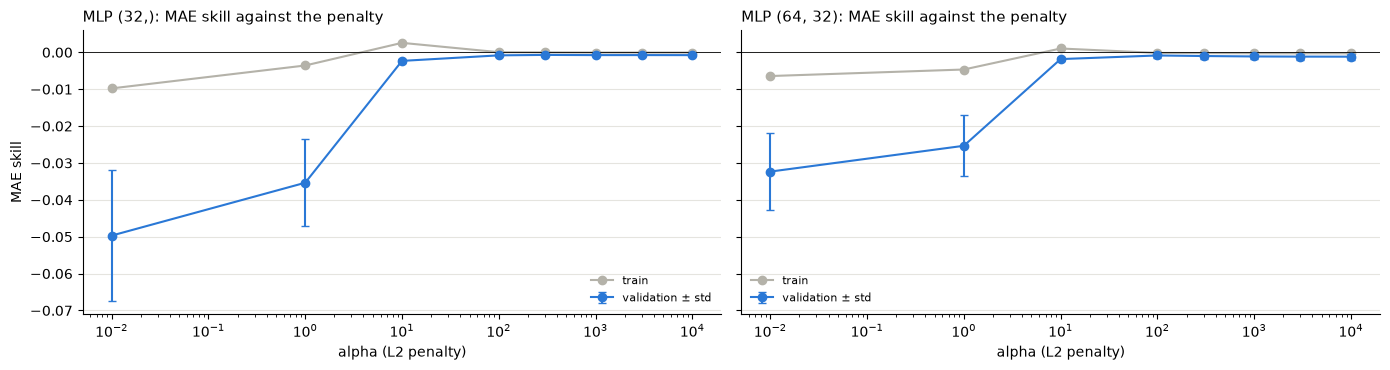

In [8]:
make_mlp = lambda **p: make_pipeline(StandardScaler(), MLPRegressor(max_iter=300, early_stopping=True, random_state=RANDOM_STATE, **p))
MLP_SIZES = [(32,), (64, 32)]
mlp_cv = val_tune(make_mlp, {"hidden_layer_sizes": MLP_SIZES, "alpha": [0.01, 1.0, 10.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0]})
p_mlp = best_params(mlp_cv, ["hidden_layer_sizes", "alpha"])
MLP_RET = f"MLP {p_mlp}"
final_report(MLP_RET, make_mlp(**p_mlp))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for a, size in zip(ax, MLP_SIZES):
    t = mlp_cv[mlp_cv["hidden_layer_sizes"].map(str) == str(size)].sort_values("alpha")
    a.plot(t["alpha"], t["train_skill"], "o-", color=GREY, label="train")
    a.errorbar(t["alpha"], t["val_skill"], yerr=t["val_skill_std"], fmt="o-", color=BLUE, capsize=3, label="validation ± std")
    a.axhline(0, color="k", lw=0.6)
    a.set_xscale("log")
    a.set_xlabel("alpha (L2 penalty)")
    a.legend(frameon=False, fontsize=8)
    tidy(a, f"MLP {size}: MAE skill against the penalty")
ax[0].set_ylabel("MAE skill")
plt.tight_layout()
plt.show()

### 3.2 RNN and LSTM on the 168-hour sequence

*(`model_test.ipynb`)* "A stacked `nn.RNN` or `nn.LSTM` reads the 168-hour sequence and a linear head maps the last hidden state to the 24 predictions." Its settings are kept: hidden size 64, 2 layers, dropout 0.2, learning rate 10⁻³, weight decay 10⁻⁴, batches of 512, at most 30 epochs, patience 5, targets divided by their train standard deviation. What changes:

| | `model_test.ipynb` | here |
|---|---|---|
| inputs | the 168 × 6 windows of the old `.npz` (OHLCV + return), global scaler or raw | 168 × 10 window-normalized channels (section 1.4, README task 6) |
| data and validation | 2017 → Oct 2026, 80/20 split; validation = the last 10% of train | the common blocks from 2020; validation Jan 2023 → Jun 2024 |
| loss | MSE | MSE, and **Huber** (README task 7): quadratic for small errors and linear for large ones (δ = 1 train standard deviation of the target), so the few extreme hours weigh less |
| final model | the early-stopped network | refitted on train + validation for the chosen number of epochs, 3 seeds averaged |

RNN, MSE loss                                 MAE=0.3199  skill=-0.0020  R2oos=-0.0021  IC=+0.003  DayDir=0.473 (p=0.94)  DayBalAcc=0.473
RNN, Huber loss                               MAE=0.3198  skill=-0.0016  R2oos=-0.0020  IC=+0.005  DayDir=0.485 (p=0.82)  DayBalAcc=0.484
LSTM, MSE loss                                MAE=0.3195  skill=-0.0007  R2oos=-0.0006  IC=+0.003  DayDir=0.501 (p=0.50)  DayBalAcc=0.500
LSTM, Huber loss                              MAE=0.3195  skill=-0.0006  R2oos=-0.0006  IC=+0.004  DayDir=0.497 (p=0.58)  DayBalAcc=0.496


,epochs,val MAE_skill,val R2_oos,val IC,"test R2_oos, single seeds",seconds
"RNN, MSE loss",3,-0.0064,-0.0056,-0.0017,-0.0032 ± 0.0002,8
"RNN, Huber loss",8,-0.0037,-0.0038,-0.0001,-0.0023 ± 0.0003,3
"LSTM, MSE loss",4,-0.0010,-0.0017,-0.0153,-0.0008 ± 0.0001,5
"LSTM, Huber loss",4,-0.0004,-0.0005,-0.0012,-0.0008 ± 0.0001,5


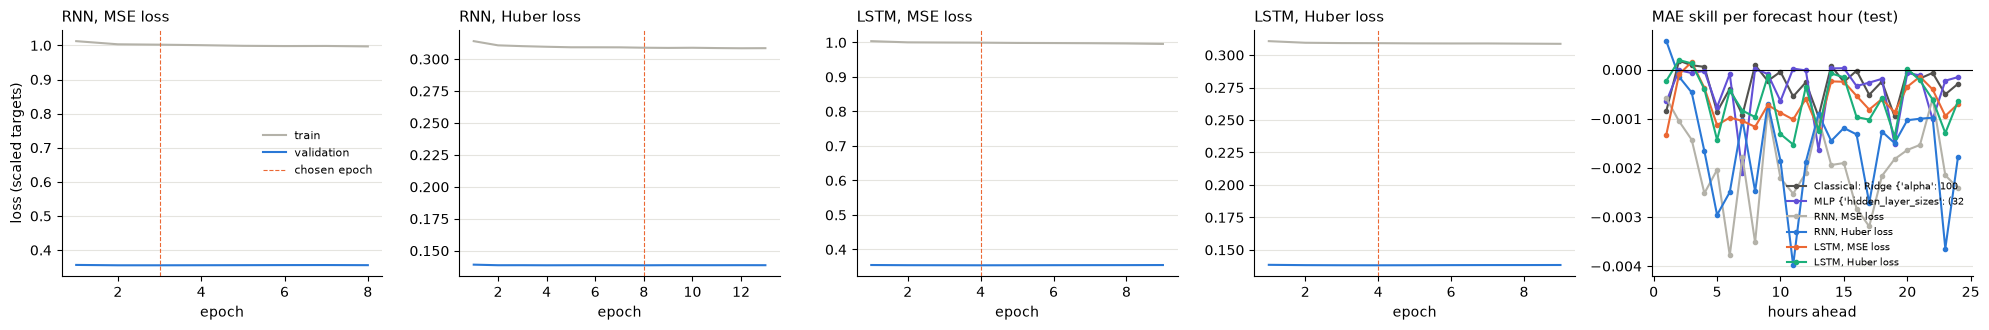

In [9]:
y_sd = Ytr.std()
RNN_KW = dict(hidden_size=64, num_layers=2, dropout=0.2)
TRAIN_KW = dict(epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512)
rnn_runs = {}
for cell in ("rnn", "lstm"):
    for loss in ("mse", "huber"):
        name = f"{cell.upper()}, {'MSE' if loss == 'mse' else 'Huber'} loss"
        make_net = lambda cell=cell: RecurrentNet(cell, len(CHANNELS), n_out=24, **RNN_KW)
        t0 = time.time()
        pv, ep, hist = early_stop_fit(make_net, S["train"], Ytr, S["val"], Yva, scale=y_sd, loss=loss, **TRAIN_KW)
        preds = refit_net(make_net, S["tv"], Ytv, S["test"], ep, scale=y_sd, loss=loss, **TRAIN_KW)
        final_report(name, pred=np.mean(preds, axis=0))
        rnn_runs[name] = {"epochs": ep, "hist": hist, **{f"val {k}": v for k, v in metrics(Yva, pv).items() if k in ("MAE_skill", "R2_oos", "IC")},
                          "test R2_oos, single seeds": seed_spread(Yte, preds, U.r2_oos), "seconds": round(time.time() - t0)}
display(pd.DataFrame.from_dict(rnn_runs, orient="index").drop(columns="hist").round(4))

fig, ax = plt.subplots(1, 5, figsize=(20, 3.4))
for a, (name, r) in zip(ax, rnn_runs.items()):
    a.plot(range(1, len(r["hist"]["train"]) + 1), r["hist"]["train"], color=GREY, label="train")
    a.plot(range(1, len(r["hist"]["val"]) + 1), r["hist"]["val"], color=BLUE, label="validation")
    a.axvline(r["epochs"], color=ORANGE, ls="--", lw=0.8, label="chosen epoch")
    a.set_xlabel("epoch")
    tidy(a, name)
ax[0].set_ylabel("loss (scaled targets)")
ax[0].legend(frameon=False, fontsize=8)
mae0_h = np.abs(Yte).mean(axis=0)
for (name, pred), c in zip([(k, v) for k, v in test_preds.items() if not k.startswith("Baseline")], [INK, PURPLE, GREY, BLUE, ORANGE, AQUA]):
    ax[4].plot(range(1, 25), 1 - np.abs(Yte - pred).mean(axis=0) / mae0_h, marker=".", color=c, label=name[:30])
ax[4].axhline(0, color="k", lw=0.8)
ax[4].set_xlabel("hours ahead")
ax[4].legend(frameon=False, fontsize=7)
tidy(ax[4], "MAE skill per forecast hour (test)")
plt.tight_layout()
plt.show()

### 3.3 Comparison on the test block

The network **chosen without the test** is the one with the best validation MAE skill (the criterion of versions 1–2).

In [10]:
summary = pd.DataFrame(results).drop_duplicates("Model", keep="last").set_index("Model")
cols = ["MAE", "RMSE", "MAE_skill", "R2_oos", "IC", "HourDirAcc", "DayDirAcc_indep", "p_value", "DayBalAcc_indep"]
display(summary[cols].sort_values("MAE").round(4))

ret_val_skill = {MLP_RET: mlp_cv.loc[0, "val_skill"], **{k: v["val MAE_skill"] for k, v in rnn_runs.items()}}
RET_CHOSEN = max(ret_val_skill, key=ret_val_skill.get)
nets = summary.loc[list(ret_val_skill)]
print(f"chosen on validation: {RET_CHOSEN} (validation MAE skill {ret_val_skill[RET_CHOSEN]:+.4f})")
SUMMARY.append({"question": "24 hourly returns", "network (chosen without the test)": f"{RET_CHOSEN} (of MLP, RNN / LSTM with MSE / Huber)",
                "test result": f"MAE skill {nets.loc[RET_CHOSEN, 'MAE_skill']:+.4f} (all networks {nets['MAE_skill'].min():+.4f} to "
                               f"{nets['MAE_skill'].max():+.4f}), IC {nets.loc[RET_CHOSEN, 'IC']:+.3f}",
                "classical reference (refitted here)": f"Ridge: MAE skill {summary.loc[f'Classical: Ridge {p_ridge}', 'MAE_skill']:+.4f}"})

,MAE,RMSE,MAE_skill,R2_oos,IC,HourDirAcc,DayDirAcc_indep,p_value,DayBalAcc_indep
Model,,,,,,,,,
Baseline: zero,0.3193,0.4925,-0.0000,0.0000,NaN,0.4960,0.4994,0.5277,0.5000
Baseline: mean per hour,0.3194,0.4926,-0.0003,-0.0003,0.0000,0.5027,0.5006,0.5000,0.5000
Classical: Ridge {'alpha': 100000.0},0.3194,0.4926,-0.0003,-0.0003,0.0012,0.5017,0.5006,0.5000,0.5000
"MLP {'hidden_layer_sizes': (32,), 'alpha': 300.0}",0.3194,0.4926,-0.0004,-0.0004,0.0000,0.5017,0.5006,0.5000,0.5000
"LSTM, Huber loss",0.3195,0.4926,-0.0006,-0.0006,0.0036,0.5017,0.4970,0.5825,0.4964
"LSTM, MSE loss",0.3195,0.4926,-0.0007,-0.0006,0.0030,0.5025,0.5006,0.5000,0.5000
"RNN, Huber loss",0.3198,0.4930,-0.0016,-0.0020,0.0047,0.5024,0.4849,0.8167,0.4844
"RNN, MSE loss",0.3199,0.4930,-0.0020,-0.0021,0.0026,0.5013,0.4729,0.9450,0.4726


chosen on validation: LSTM, Huber loss (validation MAE skill -0.0004)


### 3.4 What we see

**Answer: no. Every network ends at the zero forecast, as every classical model does.**

- The four RNN / LSTM variants and the MLP land between MAE skill −0.0020 and −0.0004 on test, with IC 0.000–0.005, daily direction accuracy 47.3–50.1% (every p ≥ 0.50) and balanced accuracy ≤ 0.500.
- **The window-normalized inputs change nothing visible.** Early stopping chose 3–8 epochs: as in `model_test.ipynb`, the validation loss stops improving almost at once.
- **The Huber loss helps very little.** It is the better loss for the RNN (MAE skill −0.0020 → −0.0016) and about the same for the LSTM (−0.0007 → −0.0006). The best network, the LSTM with Huber loss (chosen on validation), stays just below Ridge and the mean per hour (both −0.0003). Its bootstrap interval for R²_oos is [−0.0012, +0.0000] (section 8).
- **The MLP: more freedom, worse validation.** Its validation MAE skill falls from −0.0007 (alpha ≥ 100, the plateau of version 2) to −0.050 (alpha 0.01). The chosen MLP (32,), alpha 300, has test MAE skill −0.0004.

**Archived runs:** the same picture, on other data and splits.

- *Versions 1–2:* "weak regularization (alpha 0.01–1) overfits badly [...]. **The more a model is allowed to fit the training data, the worse it does on new periods.** That is the signature of a target that is mostly noise." The chosen MLP had test MAE skill −0.0008 (version 1) and −0.0004 (version 2). The 53.4% daily direction of version 1 came from predicting "always up" (balanced accuracy 0.500).
- *Early draft:* MLP (64, 32), alpha 1: test MAE 0.3289, daily direction 50.6%.
- *`model_test.ipynb`, README:* "All four variants end up equal to the zero forecast (MSE ratio 1.000–1.002) with ~50% direction accuracy. The training loss barely moves from the first epoch."

## 4. The direction of the next hour

**Question.** Will the next hour go up or down? In particular, can a sequence model see more than the reversal of the last hour?

**To beat.** The classical models found "a real but small effect for **one hour ahead only**" (`v3-extensions.ipynb`, section 5): mostly a reversal, where the next hour tends to go the opposite way of the last one. Gradient Boosting reaches AUC 0.533 on the base features (0.538 with the Binance attributes) and the plain reversal rule 0.528 (`classical-models.ipynb`, section 5).

**Models.**

| Model | Input | How it is tuned |
|---|---|---|
| Reversal rule | the last hour | no learning: "the next hour goes the opposite way of the last hour" |
| Gradient Boosting classifier (classical reference) | the 42 base features | grid of `classical-models.ipynb`, by validation AUC |
| MLP classifier (scikit-learn) | the 42 base features | size, L2 penalty and number of epochs (`max_iter`, early stopping off), by validation AUC |
| LSTM classifier | the 168-hour sequence | binary cross-entropy, early stopping on validation. It sees the last hours directly, with their size, range and volume |

The Binance attributes are left out: in `classical-models.ipynb` they lift the AUC of Gradient Boosting only from 0.533 to 0.538 (section 5) and add nothing for the size of the moves (section 6.4).

**Every origin.** For this target neighbouring origins do *not* share their target: each one predicts a different hour. Keeping every 6th origin throws away 5/6 of the examples, so Gradient Boosting and the LSTM are also trained on every origin.

**Metrics** on every test hour (≈ 19,800): AUC, and the accuracy of the 10% most confident calls, with a binomial test against 50%.

,val AUC,AUC,accuracy top 10%,p-value,"test AUC, single seeds"
Reversal rule,0.5460,0.5278,0.5459,2.4e-05,
"Classical: GB classifier {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 200}",0.5535,0.5328,0.5393,2.5e-04,
"Classical: GB classifier, every origin {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 200}",0.5687,0.5409,0.5590,8.2e-08,
"MLP classifier {'alpha': 10.0, 'hidden_layer_sizes': (64, 32), 'max_iter': 30}",0.5454,0.5311,0.5494,5.9e-06,0.5306 ± 0.0007
LSTM classifier (3 epochs),0.5200,0.5187,0.5449,3.5e-05,0.5184 ± 0.0022
"LSTM classifier, every origin (13 epochs)",0.5653,0.5378,0.5943,2.3e-17,0.5372 ± 0.0007


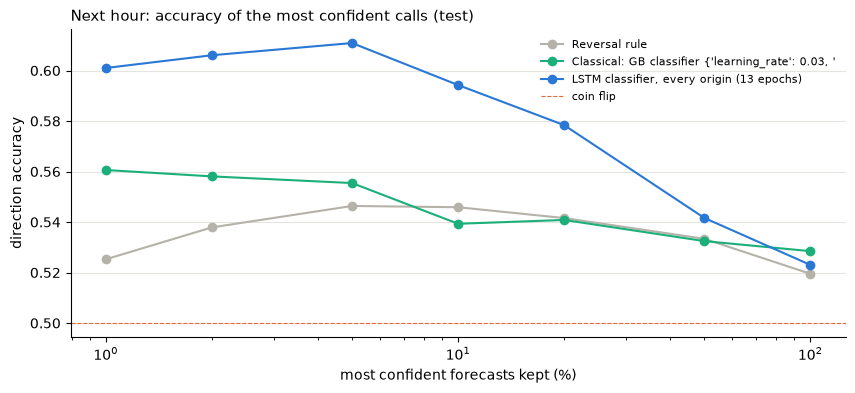

In [11]:
y1 = {k: Y[k][:, 0] for k in P}                                      # the next hour's return
up = {k: (v > 0).astype(np.float32) for k, v in y1.items()}


def direction_row(score, y):
    nz = y != 0
    score, y = score[nz], y[nz]
    centred = score - np.median(score)
    top = np.argsort(-np.abs(centred))[:len(score) // 10]
    hits = (centred[top] > 0) == (y[top] > 0)
    return {"AUC": roc_auc_score(y > 0, score), "accuracy top 10%": hits.mean(),
            "p-value": stats.binomtest(int(hits.sum()), len(top), 0.5, alternative="greater").pvalue}


def tune_by_auc(make, grid, Xa, ya, Xv, yv):
    # Fit each setting on (Xa, ya > 0), AUC on the validation block -> (best setting, its AUC)
    grid = list(ParameterGrid(grid))
    auc = [roc_auc_score(yv > 0, make(**p).fit(Xa, ya > 0).predict_proba(Xv)[:, 1]) for p in grid]
    return grid[int(np.argmax(auc))], max(auc)


dir_rows, dir_scores = {}, {}


def add_dir(name, val_auc, score, seed_scores=None):
    dir_scores[name] = score
    dir_rows[name] = {"val AUC": val_auc, **direction_row(score, y1["test"]),
                      "test AUC, single seeds": seed_spread(y1["test"] > 0, seed_scores, roc_auc_score) if seed_scores else ""}


add_dir("Reversal rule", roc_auc_score(y1["val"] > 0, -FEAT["ret_lag1"].values[P["val"]]), -FEAT["ret_lag1"].values[P["test"]])

make_clf = lambda **p: HistGradientBoostingClassifier(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
CLF_GRID = {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "min_samples_leaf": [200, 1000]}
for tag, tr, tv in [("", "train", "tv"), (", every origin", "train1", "tv1")]:
    p, auc = tune_by_auc(make_clf, CLF_GRID, Xw(tr, BASE), y1[tr], Fva, y1["val"])
    add_dir(f"Classical: GB classifier{tag} {p}", auc, make_clf(**p).fit(Xw(tv, BASE), y1[tv] > 0).predict_proba(Fte)[:, 1])
GB_DIR = [k for k in dir_rows if k.startswith("Classical: GB classifier {")][0]

make_mlpc = lambda seed=RANDOM_STATE, **p: make_pipeline(StandardScaler(), MLPClassifier(early_stopping=False, random_state=seed, **p))
p_mlpc, auc = tune_by_auc(make_mlpc, {"hidden_layer_sizes": [(32,), (64, 32)], "alpha": [0.1, 1.0, 10.0, 100.0], "max_iter": [10, 30, 100]},
                          Ftr, y1["train"], Fva, y1["val"])
probas = [make_mlpc(seed=RANDOM_STATE + s, **p_mlpc).fit(Ftv, y1["tv"] > 0).predict_proba(Fte)[:, 1] for s in range(N_SEEDS)]
add_dir(f"MLP classifier {p_mlpc}", auc, np.mean(probas, axis=0), probas)

S["train1"], S["tv1"] = seq("train1"), seq("tv1")                   # every origin (also used in section 5)
make_lstm_clf = lambda: RecurrentNet("lstm", len(CHANNELS), hidden_size=64, num_layers=2, dropout=0.2, n_out=1)
CLF_KW = dict(loss="bce", epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512)
lstm_clf_hist = {}
for tag, tr, tv in [("", "train", "tv"), (", every origin", "train1", "tv1")]:
    pv, ep, lstm_clf_hist[tag] = early_stop_fit(make_lstm_clf, S[tr], up[tr], S["val"], up["val"], **CLF_KW)
    logits = refit_net(make_lstm_clf, S[tv], up[tv], S["test"], ep, **CLF_KW)
    add_dir(f"LSTM classifier{tag} ({ep} epochs)", roc_auc_score(up["val"], pv), np.mean(logits, axis=0), logits)

dir_tab = pd.DataFrame.from_dict(dir_rows, orient="index")
display(dir_tab.assign(**{"p-value": dir_tab["p-value"].map("{:.1e}".format)}).round(4))

SHARES = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]


def confidence_curve(score, y):
    # Direction accuracy on the q most confident forecasts (|score - median| largest), zero returns left out
    nz = y != 0
    c = score[nz] - np.median(score[nz])
    hits = ((c > 0) == (y[nz] > 0))[np.argsort(-np.abs(c))]
    return [hits[:max(1, int(len(hits) * q))].mean() for q in SHARES]


nets_dir = [k for k in dir_rows if not k.startswith(("Reversal", "Classical"))]
DIR_CHOSEN = max(nets_dir, key=lambda k: dir_rows[k]["val AUC"])
fig, ax = plt.subplots(figsize=(10, 4))
for k, c in zip(["Reversal rule", GB_DIR, DIR_CHOSEN], [GREY, AQUA, BLUE]):
    ax.plot([100 * q for q in SHARES], confidence_curve(dir_scores[k], y1["test"]), "o-", color=c, label=k[:50])
ax.axhline(0.5, color=ORANGE, ls="--", lw=0.8, label="coin flip")
ax.set_xscale("log")
ax.set_xlabel("most confident forecasts kept (%)")
ax.set_ylabel("direction accuracy")
ax.legend(frameon=False, fontsize=8)
tidy(ax, "Next hour: accuracy of the most confident calls (test)")
plt.show()

SUMMARY.append({"question": "direction of the next hour", "network (chosen without the test)": f"{DIR_CHOSEN.split(' {')[0]} (best validation AUC)",
                "test result": f"AUC {dir_rows[DIR_CHOSEN]['AUC']:.3f}, top 10% right {dir_rows[DIR_CHOSEN]['accuracy top 10%']:.1%} "
                               f"(p = {dir_rows[DIR_CHOSEN]['p-value']:.0e})",
                "classical reference (refitted here)": f"GB AUC {dir_rows[GB_DIR]['AUC']:.3f}; reversal rule {dir_rows['Reversal rule']['AUC']:.3f}"})

### 4.1 What we see

**Answer: no network beats Gradient Boosting on AUC. The LSTM catches up only when it is trained on every origin.**

- The LSTM classifier trained on every origin is the network chosen on validation (validation AUC 0.565, the highest of the networks). On test it has AUC **0.538**, and its 10% most confident calls are right **59.4%** of the time (p = 2×10⁻¹⁷). Against Gradient Boosting on every 6th origin (0.533) the difference is +0.005, interval [−0.001, +0.012] (section 8): a tie, although the LSTM is ahead in 94% of the resamples. Gradient Boosting trained on every origin has the best validation AUC of all models (0.569) and the best test AUC (0.541).
- **The gain comes from more rows, not from the network.** The same LSTM on every 6th origin stops after 3 epochs with AUC 0.519, below the reversal rule (0.528); the MLP classifier has 0.531. Every origin lifts the LSTM from 0.519 to 0.538 and Gradient Boosting from 0.533 to 0.541.
- **The confident calls** of the LSTM (59.4%, against 53.9% for Gradient Boosting and 55.9% for Gradient Boosting on every origin) are the one place where it looks better. Section 8 does not test this difference, and the AUC over all hours is not better, so it is a lead to check, not a result.
- Single seeds spread by ±0.0007–0.0022 AUC, as much as the differences between the best models.
- As in the classical notebook, the effect is small (about 55–60 right out of 100 confident calls) and comes before any trading costs.

**Archived runs:** no archived notebook trained a network on this target. *(`v3-extensions.ipynb`, section 5)* "The reversal is stable [...]: the simple rule still has AUC 0.528, and its 10% most confident forecasts are right 54.6% of the time. [...] Gradient Boosting adds a little: AUC 0.537 on base features."

## 5. The size of each hourly move (main experiment)

**Question.** How large will each of the next 24 hourly moves be? The target is **|r|, the absolute return of each hour**, in %. *(`bitcoin-models-v3.ipynb`, section 5)* "The **size** of hourly moves is strongly autocorrelated while the direction is not." This is where the classical models find the clearest hourly signal, and one of the targets that task 7 of the README asks the recurrent networks to try. Models are trained with squared error and judged by R².

**To beat.** Two classical references, refitted here on the same rows and with the same inputs as the networks (section 5.1):

- **(a) Gradient Boosting fitted once** on train + validation, in long format;
- **(b) Gradient Boosting refitted every month** on everything known before the month, with more weight on recent months, as in `classical-models.ipynb` (section 6.5). This is the best classical model for this target.

The verdict is given against the better of the two on validation. The best simple rule, last week's average |r| × the hour-of-day profile, is shown too.

**Experiments.**

| Experiment | Input | Output | Question it answers |
|---|---|---|---|
| **inputs** (5.1) | base + per-hour columns, with or without B3, B4, B5 and the recent hour profile | — | which inputs to use, chosen once with Gradient Boosting, as in `classical-models.ipynb` |
| **MLP, long format** (5.2) | the chosen columns, standardized | one \|r\| per row | on the very same rows as Gradient Boosting, is a network better than trees? |
| **LSTM** (5.3) | the 168 × 10 sequence (section 1.4) | the 24 \|r\| of the next day | can a network build its own features from the raw week? |
| **LSTM + hour features** (5.3) | the sequence and, for each predicted hour, its clock, recent profile and releases | the 24 \|r\| of the next day | does the LSTM gain from knowing which hours it predicts? |
| **every origin, monthly refits** (5.4) | the same | the same | do the networks gain from 6× more (overlapping) rows, or from being refitted every month like Gradient Boosting? |
| **ensembles** (5.5) | — | average of Gradient Boosting and the networks | do two model families make different errors that cancel when averaged? |

### 5.1 Inputs and the classical references

**Inputs.** Gradient Boosting in long format is tuned on the base columns with the grid of `classical-models.ipynb` (section 6.1). With that setting fixed, each candidate set of inputs is fitted on train and scored on validation, as in `classical-models.ipynb` (section 6.4); the set with the best validation R² (`CHOSEN_SET`) is used by Gradient Boosting and by the MLP. "base" alone is shown for comparison and is not a candidate. The test R² is shown for information only.

**(a) Fitted once.** Gradient Boosting with `CHOSEN_SET`, fitted on train + validation.

In [12]:
ya = {k: yl(k) for k in ("train", "val", "test", "tv")}
abs_sd = ya["train"].std()


def abs_baselines(block):
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return {"Baseline: training mean": np.full(len(p), ya["train"].mean()),
            "Baseline: last week": week_abs[p],
            "Baseline: last week x hour profile": rule_abs(block)}


make_abs_gb = lambda **p: make_gb(min_samples_leaf=1000, **p)
print("Gradient Boosting on the base columns, validation block")
_, p_abs_gb = tune(make_abs_gb, {"learning_rate": [0.05, 0.1], "max_depth": [2, 3, 6]},
                   Xl("train", BASE), ya["train"], Xl("val", BASE), ya["val"], vol_scores)

feat_rows = {}
for name, (cols, hcols) in FSETS.items():                           # the setting above, fixed: only the inputs change
    Xtr_l, Xva_l = Xl("train", cols, hcols), Xl("val", cols, hcols)
    feat_rows[name] = {"n_features": Xtr_l.shape[1],
                       "val R2": U.r2(ya["val"], make_abs_gb(**p_abs_gb).fit(Xtr_l, ya["train"]).predict(Xva_l)),
                       "test R2": U.r2(ya["test"], make_abs_gb(**p_abs_gb).fit(Xl("tv", cols, hcols), ya["tv"])
                                       .predict(Xl("test", cols, hcols)))}
del Xtr_l, Xva_l
feat_tab = pd.DataFrame.from_dict(feat_rows, orient="index")
CHOSEN_SET = feat_tab.drop("base")["val R2"].idxmax()
print("Input sets, Gradient Boosting fitted once (test R2 for information only)")
display(feat_tab.round(4))
print(f"chosen on validation: {CHOSEN_SET}")

COLS, HCOLS = FSETS[CHOSEN_SET]
XA = {k: Xl(k, COLS, HCOLS) for k in ("train", "val", "test", "tv")}
GB_ABS = "Classical: GB, fitted once"
abs_val = {**abs_baselines("val"), GB_ABS: make_abs_gb(**p_abs_gb).fit(XA["train"], ya["train"]).predict(XA["val"])}
abs_test = {**abs_baselines("test"), GB_ABS: make_abs_gb(**p_abs_gb).fit(XA["tv"], ya["tv"]).predict(XA["test"])}
abs_seeds = {}

Gradient Boosting on the base columns, validation block


,learning_rate,max_depth,score,MAE,corr,seconds
0,0.10,6,0.0966,0.2224,0.3135,1.7
1,0.05,6,0.0959,0.2241,0.3127,1.8
2,0.05,3,0.0932,0.2260,0.3089,1.3
3,0.10,3,0.0921,0.2238,0.3061,1.3
4,0.10,2,0.0915,0.2258,0.3058,1.1
5,0.05,2,0.0901,0.2288,0.3067,1.2


Input sets, Gradient Boosting fitted once (test R2 for information only)


,n_features,val R2,test R2
base,47,0.0966,0.1292
base + B3,52,0.0947,0.1295
base + B3 + B4,55,0.0876,0.1277
base + B3 + B5,57,0.0941,0.1311
base + B3 + B4 + B5,60,0.0894,0.1298
base + B3 + B4 + B5 + recent profile,61,0.0923,0.1377


chosen on validation: base + B3


**(b) Refitted every month.** The logic of `classical-models.ipynb` (section 6.5): for every month of the validation or test block, Gradient Boosting is refitted on every 6th origin of the whole series whose 24 target hours ended **before the month starts**, and predicts that month.

| Variant | Training rows |
|---|---|
| Monthly, expanding | everything before the month |
| Monthly, last 24 months | a rolling window |
| Monthly, half-life 6 / 12 months | everything, with weight `0.5 ** (age in months / half-life)` |

The variant is chosen on the validation block (the same simulation over Jan 2023 → Jun 2024) and run once on test. The MLP is refitted with the same variant in section 5.4.

In [13]:
pool = np.arange(len(origins))[::STRIDE]                             # every 6th origin of the whole series
P["pool"], Y["pool"], D["pool"] = pos_all[pool], y_all[pool], origins[pool]
X_pool, y_pool = Xl("pool", COLS, HCOLS), yl("pool")
pool_end, pool_origin = np.repeat(day_end[pool], 24), np.repeat(origins[pool], 24)
REFIT = {"Monthly, expanding": {}, "Monthly, last 24 months": {"window": 24},
         "Monthly, half-life 6 months": {"half_life": 6}, "Monthly, half-life 12 months": {"half_life": 12}}


def month_fit_rows(start, window=None, half_life=None):
    fit = pool_end < start                                           # targets known before the month
    if window:
        fit &= pool_origin >= start - pd.DateOffset(months=window)
    w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / half_life) if half_life else None
    return fit, w


def refit_monthly(block, X_b, X_fit, fit_predict, **kw):
    # Every month of the block: fit_predict(X, y, weights, X_month) on the pool rows known before the month
    org = np.repeat(D[block], 24)
    pred = np.empty(len(X_b))
    for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
        start = m.start_time
        fit, w = month_fit_rows(start, **kw)
        rows_m = (org >= start) & (org < (m + 1).start_time)
        pred[rows_m] = fit_predict(X_fit[fit], y_pool[fit], w, X_b[rows_m])
    return pred


gb_month = lambda X, y, w, X_new: make_abs_gb(**p_abs_gb).fit(X, y, sample_weight=w).predict(X_new)
t0 = time.time()
gb_refit_val = {v: refit_monthly("val", XA["val"], X_pool, gb_month, **kw) for v, kw in REFIT.items()}
refit_tab = pd.DataFrame({"val R2": {"Fit once": U.r2(ya["val"], abs_val[GB_ABS]),
                                     **{v: U.r2(ya["val"], p) for v, p in gb_refit_val.items()}}})
REFIT_CHOSEN = refit_tab["val R2"].drop("Fit once").idxmax()
GB_REFIT = f"Classical: GB, {REFIT_CHOSEN.lower()}"
abs_val[GB_REFIT] = gb_refit_val[REFIT_CHOSEN]
abs_test[GB_REFIT] = refit_monthly("test", XA["test"], X_pool, gb_month, **REFIT[REFIT_CHOSEN])
refit_tab["test R2"] = pd.Series({"Fit once": U.r2(ya["test"], abs_test[GB_ABS]), REFIT_CHOSEN: U.r2(ya["test"], abs_test[GB_REFIT])})
print(f"chosen on validation: {REFIT_CHOSEN} ({time.time() - t0:.0f} s)")
display(refit_tab.round(4))

chosen on validation: Monthly, half-life 12 months (1283 s)


,val R2,test R2
Fit once,0.0947,0.1295
"Monthly, expanding",0.1005,NaN
"Monthly, last 24 months",0.0963,NaN
"Monthly, half-life 6 months",0.0872,NaN
"Monthly, half-life 12 months",0.1005,0.1479


### 5.2 MLP in long format

The columns of `CHOSEN_SET` (5.1), standardized with the train block's mean and standard deviation. A small grid of size and weight decay, dropout 0.1, AdamW with learning rate 10⁻³, batches of 2,048 rows, at most 40 epochs with patience 5.

In [14]:
sc_abs = StandardScaler().fit(XA["train"])
XA_s = {k: sc_abs.transform(v).astype(np.float32) for k, v in XA.items()}
ABS_MLP_KW = dict(epochs=40, patience=5, lr=1e-3, batch=2048)


def mlp_abs_spec(hidden, weight_decay):
    return (lambda: MLPNet(XA_s["train"].shape[1], hidden, n_out=1, dropout=0.1)), {"weight_decay": weight_decay}


_, mlp_abs_best = nn_grid(mlp_abs_spec, {"hidden": [(64, 32), (256, 128)], "weight_decay": [1e-4, 1e-2]},
                          XA_s["train"], ya["train"], XA_s["val"], ya["val"], vol_scores, scale=abs_sd, **ABS_MLP_KW)
MLP_ABS = f"MLP, long format {mlp_abs_best['params']}"
abs_val[MLP_ABS] = mlp_abs_best["val"]
abs_seeds[MLP_ABS] = refit_best(mlp_abs_spec, mlp_abs_best, XA_s["tv"], ya["tv"], XA_s["test"], abs_sd, **ABS_MLP_KW)

,hidden,weight_decay,score,MAE,corr,epochs,seconds
2,"(256, 128)",0.0001,0.0974,0.2233,0.3166,9,2.6
3,"(256, 128)",0.0100,0.0966,0.2183,0.3137,13,3.5
1,"(64, 32)",0.0100,0.0952,0.2216,0.3105,9,2.8
0,"(64, 32)",0.0001,0.0951,0.2216,0.3103,9,2.8


### 5.3 LSTM on the 168-hour sequence

The architecture of `model_test.ipynb` (2 layers, dropout 0.2) with a small grid of hidden sizes; at most 60 epochs with patience 8. One network predicts the 24 values of the next day, so its output, flattened origin by origin, lines up with the rows of the long format. This LSTM knows the clock of the hours it has read, but not which hours it predicts: its linear head has one output per hour ahead, and the same "hour 5 ahead" can be 4:00 on a Sunday or 14:00 on a CPI day.

In [15]:
LSTM_KW = dict(epochs=60, patience=8, lr=1e-3, weight_decay=1e-4, batch=512)
r2_flat = lambda y, p: vol_scores(np.ravel(y), np.ravel(p))


def lstm_abs_spec(hidden_size):
    return (lambda: RecurrentNet("lstm", len(CHANNELS), hidden_size=hidden_size, num_layers=2, dropout=0.2, n_out=24)), {}


_, lstm_abs_best = nn_grid(lstm_abs_spec, {"hidden_size": [32, 64, 128]}, S["train"], np.abs(Y["train"]), S["val"], np.abs(Y["val"]),
                           r2_flat, scale=abs_sd, **LSTM_KW)
LSTM_ABS = f"LSTM {lstm_abs_best['params']}"
abs_val[LSTM_ABS] = lstm_abs_best["val"].reshape(-1)
abs_seeds[LSTM_ABS] = [q.reshape(-1) for q in refit_best(lstm_abs_spec, lstm_abs_best, S["tv"], np.abs(Y["tv"]), S["test"], abs_sd, **LSTM_KW)]

,hidden_size,score,MAE,corr,epochs,seconds
2,128,0.0999,0.2229,0.3173,31,19.5
1,64,0.0959,0.2223,0.3105,39,7.7
0,32,0.0958,0.2216,0.3111,59,5.2


**LSTM + hour features.** The same LSTM encoder reads the same sequence, but the output is built hour by hour (`FutureHeadLSTM`, section 2): for each predicted hour *h*, a small head (one hidden layer of 64 units, ReLU, dropout 0.2) reads the last hidden state together with the features of hour *h*: `h_ahead`, hour of day and weekday (sine and cosine), `tgt_weekend`, `tgt_hour_profile_recent` and B5. They are standardized with the train block. The head is shared by the 24 hours, so what it learns about a CPI hour or a weekend applies at every horizon. Same grid, epochs and patience as above, trained on every 6th origin. The better of the two LSTMs on validation is the one trained on every origin in section 5.4.

In [16]:
FUT = H_BASE + ["tgt_weekend"] + RECENT + B5                         # features of each predicted hour
_f = Xl("train", [], FUT)
FUT_MU, FUT_SD = _f.mean(axis=0), np.where(_f.std(axis=0) > 0, _f.std(axis=0), 1.0)
del _f


def seq_fut(block):
    # one row per origin: the standardized sequence of 1.4, then the standardized features of its 24 predicted hours
    f = ((Xl(block, [], FUT) - FUT_MU) / FUT_SD).reshape(len(P[block]), -1)
    return np.hstack([S[block].reshape(len(S[block]), -1), f]).astype(np.float32)


SF = {k: seq_fut(k) for k in ("train", "val", "test", "tv")}


def lstm_fut_spec(hidden_size):
    return (lambda: FutureHeadLSTM(len(CHANNELS), len(FUT), hidden_size=hidden_size, num_layers=2, dropout=0.2)), {}


_, lstm_fut_best = nn_grid(lstm_fut_spec, {"hidden_size": [32, 64, 128]}, SF["train"], np.abs(Y["train"]), SF["val"],
                           np.abs(Y["val"]), r2_flat, scale=abs_sd, **LSTM_KW)
LSTM_FUT = f"LSTM + hour features {lstm_fut_best['params']}"
abs_val[LSTM_FUT] = lstm_fut_best["val"].reshape(-1)
abs_seeds[LSTM_FUT] = [q.reshape(-1) for q in refit_best(lstm_fut_spec, lstm_fut_best, SF["tv"], np.abs(Y["tv"]), SF["test"],
                                                         abs_sd, **LSTM_KW)]
LSTM_WIN = max([LSTM_ABS, LSTM_FUT], key=lambda k: U.r2(ya["val"], abs_val[k]))
display(pd.DataFrame({k: {"val R2": U.r2(ya["val"], abs_val[k]), "epochs": b["epochs"]}
                      for k, b in [(LSTM_ABS, lstm_abs_best), (LSTM_FUT, lstm_fut_best)]}).T.round(4))
print(f"better on validation (trained on every origin in 5.4): {LSTM_WIN}")

,hidden_size,score,MAE,corr,epochs,seconds
2,128,0.1225,0.2141,0.3505,24,16.0
1,64,0.1200,0.2202,0.3477,24,5.7
0,32,0.1190,0.2184,0.3451,37,4.4


,val R2,epochs
LSTM {'hidden_size': 128},0.0999,31.0
LSTM + hour features {'hidden_size': 128},0.1225,24.0


better on validation (trained on every origin in 5.4): LSTM + hour features {'hidden_size': 128}


### 5.4 Every origin and monthly refits

**Every origin.** The settings chosen above, trained on every origin of the train block (early stopping on the same validation block) and refitted on every origin of train + validation. Gradient Boosting is retrained the same way. Only the LSTM that was better on validation in 5.3 is trained here: on every origin an LSTM takes most of the run time of the notebook.

**Monthly refits of the MLP.** The variant chosen for Gradient Boosting in 5.1 (b), with the setting and the number of epochs chosen in 5.2. Each month the MLP is trained from scratch on the pool of 5.1 (b), with the row weights of the variant. On validation one seed (as for the other networks); on test 3 seeds, averaged. The inputs keep the scaler of the train block.

In [17]:
XA1 = {k: Xl(k, COLS, HCOLS) for k in ("train1", "tv1")}
ya1 = {k: yl(k) for k in ("train1", "tv1")}
GB_ABS1 = f"{GB_ABS}, every origin"
abs_val[GB_ABS1] = make_abs_gb(**p_abs_gb).fit(XA1["train1"], ya1["train1"]).predict(XA["val"])
abs_test[GB_ABS1] = make_abs_gb(**p_abs_gb).fit(XA1["tv1"], ya1["tv1"]).predict(XA["test"])
XA1 = {k: sc_abs.transform(v).astype(np.float32) for k, v in XA1.items()}

# the LSTM that was better on validation in 5.3, with its own input
fut_wins = LSTM_WIN == LSTM_FUT
lstm_spec, lstm_best, LX = (lstm_fut_spec, lstm_fut_best, SF) if fut_wins else (lstm_abs_spec, lstm_abs_best, S)
LX1 = {k: seq_fut(k) for k in ("train1", "tv1")} if fut_wins else {k: S[k] for k in ("train1", "tv1")}
MLP_ABS1, LSTM_ABS1 = f"{MLP_ABS}, every origin", f"{LSTM_WIN}, every origin"

more_data = {}
for name, spec, best, X1, y1_, Xv, yv, Xte, kw in [
        (MLP_ABS1, mlp_abs_spec, mlp_abs_best, XA1, ya1, XA_s["val"], ya["val"], XA_s["test"], ABS_MLP_KW),
        (LSTM_ABS1, lstm_spec, lstm_best, LX1, {k: np.abs(Y[k]) for k in ("train1", "tv1")}, LX["val"], np.abs(Y["val"]),
         LX["test"], LSTM_KW)]:
    t0 = time.time()
    make_net, tkw = spec(**best["params"])
    pv, ep, _ = early_stop_fit(make_net, X1["train1"], y1_["train1"], Xv, yv, abs_sd, **{**kw, **tkw})
    abs_val[name] = pv.reshape(-1)
    abs_seeds[name] = [q.reshape(-1) for q in refit_net(make_net, X1["tv1"], y1_["tv1"], Xte, ep, abs_sd, **{**kw, **tkw})]
    more_data[name] = {"epochs": ep, "val R2": U.r2(ya["val"], abs_val[name]), "seconds": round(time.time() - t0)}
del XA1, ya1, LX1

# monthly refits of the MLP: the variant chosen for Gradient Boosting in 5.1, the number of epochs chosen in 5.2
t0 = time.time()
X_pool_s = sc_abs.transform(X_pool).astype(np.float32)
make_mlp_net, mlp_tkw = mlp_abs_spec(**mlp_abs_best["params"])
mlp_kw = {k: v for k, v in {**ABS_MLP_KW, **mlp_tkw}.items() if k not in ("epochs", "patience")}


def mlp_month(seed):
    def fit_predict(X, y, w, X_new):
        net, _ = train_net(make_mlp_net, X, y / abs_sd, epochs=mlp_abs_best["epochs"], w=w, seed=seed, **mlp_kw)
        return predict_net(net, X_new) * abs_sd
    return fit_predict


MLP_REFIT = f"MLP, long format, {REFIT_CHOSEN.lower()}"
abs_val[MLP_REFIT] = refit_monthly("val", XA_s["val"], X_pool_s, mlp_month(RANDOM_STATE), **REFIT[REFIT_CHOSEN])
abs_seeds[MLP_REFIT] = [refit_monthly("test", XA_s["test"], X_pool_s, mlp_month(RANDOM_STATE + s), **REFIT[REFIT_CHOSEN])
                        for s in range(N_SEEDS)]
more_data[MLP_REFIT] = {"epochs": mlp_abs_best["epochs"], "val R2": U.r2(ya["val"], abs_val[MLP_REFIT]),
                        "seconds": round(time.time() - t0)}
display(pd.DataFrame.from_dict(more_data, orient="index").round(4))

,epochs,val R2,seconds
"MLP, long format {'hidden': (256, 128), 'weight_decay': 0.0001}, every origin",2,0.1031,17
"LSTM + hour features {'hidden_size': 128}, every origin",5,0.1227,75
"MLP, long format, monthly, half-life 12 months",9,0.0945,321


### 5.5 Test block

Every model is evaluated once on the test block (every origin × 24 hours): fitted once on train + validation, or refitted every month. The ensembles average Gradient Boosting with the networks, without weights, so they add no hyperparameter to overfit. "LSTM" in an ensemble is the LSTM that was better on validation in 5.3. The model to choose is the one with the best **validation** R². For the networks fitted once it comes from the early-stopped fit on the train block (one seed), for the monthly refits from the same monthly simulation on the validation block, and for the ensembles from the average of those validation forecasts.

,val R2,test R2,test MAE,test corr,"test R2, single seeds"
Baseline: training mean,-0.2656,-0.2385,0.3356,NaN,
Baseline: last week,0.0355,0.0377,0.2369,0.2087,
Baseline: last week x hour profile,0.0497,0.0560,0.2345,0.2442,
"Classical: GB, fitted once",0.0947,0.1295,0.2220,0.3613,
"Classical: GB, monthly, half-life 12 months",0.1005,0.1479,0.2208,0.3859,
"Classical: GB, fitted once, every origin",0.0902,0.1281,0.2221,0.3617,
"MLP, long format {'hidden': (256, 128), 'weight_decay': 0.0001}",0.0974,0.1314,0.2171,0.3661,0.1251 ± 0.0032
LSTM {'hidden_size': 128},0.0999,0.0980,0.2301,0.3156,0.0935 ± 0.0056
LSTM + hour features {'hidden_size': 128},0.1225,0.1317,0.2239,0.3637,0.1273 ± 0.0049
"MLP, long format {'hidden': (256, 128), 'weight_decay': 0.0001}, every origin",0.1031,0.1406,0.2168,0.3769,0.1359 ± 0.0012


chosen on validation (networks and ensembles): LSTM + hour features {'hidden_size': 128}, every origin
best classical reference on validation: Classical: GB, monthly, half-life 12 months
test R2: 0.1322 against 0.1479 (-0.0157)


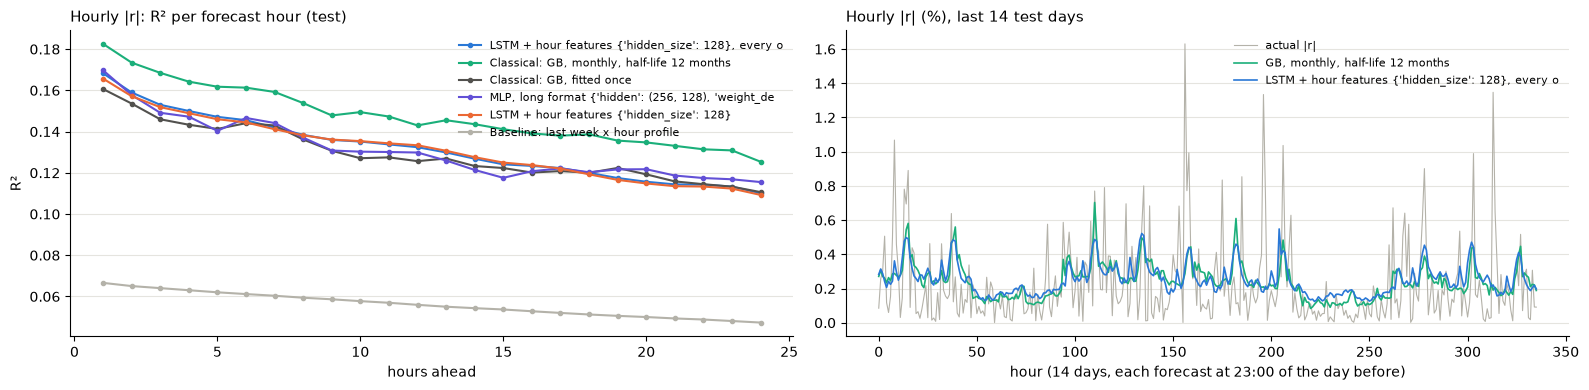

In [18]:
for k, v in abs_seeds.items():
    abs_test[k] = np.mean(v, axis=0)
ENS_ABS = {"Ensemble: GB + MLP": [GB_ABS, MLP_ABS], "Ensemble: GB + LSTM": [GB_ABS, LSTM_WIN],
           "Ensemble: GB + MLP + LSTM": [GB_ABS, MLP_ABS, LSTM_WIN],
           "Ensemble, every origin: GB + MLP + LSTM": [GB_ABS1, MLP_ABS1, LSTM_ABS1],
           "Ensemble, monthly refits: GB + MLP": [GB_REFIT, MLP_REFIT],
           "Ensemble: GB + MLP monthly refits, LSTM every origin": [GB_REFIT, MLP_REFIT, LSTM_ABS1]}
for e, members in ENS_ABS.items():
    abs_val[e] = np.mean([abs_val[m] for m in members], axis=0)
    abs_test[e] = np.mean([abs_test[m] for m in members], axis=0)

abs_tab = pd.DataFrame.from_dict({k: {"val R2": U.r2(ya["val"], abs_val[k]), "test R2": U.r2(ya["test"], v),
                                       "test MAE": mean_absolute_error(ya["test"], v), "test corr": safe_corr(v, ya["test"]),
                                       "test R2, single seeds": seed_spread(ya["test"], abs_seeds[k], U.r2) if k in abs_seeds else ""}
                                   for k, v in abs_test.items()}, orient="index")
with pd.option_context("display.max_colwidth", 60):
    display(abs_tab.round(4))
ABS_CHOSEN = abs_tab.drop([k for k in abs_tab.index if k.startswith(("Baseline", "Classical"))])["val R2"].idxmax()
REF_BEST = max([GB_ABS, GB_REFIT], key=lambda k: abs_tab.loc[k, "val R2"])
print(f"chosen on validation (networks and ensembles): {ABS_CHOSEN}")
print(f"best classical reference on validation: {REF_BEST}")
print(f"test R2: {abs_tab.loc[ABS_CHOSEN, 'test R2']:.4f} against {abs_tab.loc[REF_BEST, 'test R2']:.4f} "
      f"({abs_tab.loc[ABS_CHOSEN, 'test R2'] - abs_tab.loc[REF_BEST, 'test R2']:+.4f})")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ac = ya["test"].reshape(-1, 24)
for k, c in [(ABS_CHOSEN, BLUE), (GB_REFIT, AQUA), (GB_ABS, INK), (MLP_ABS, PURPLE), (LSTM_WIN, ORANGE),
             ("Baseline: last week x hour profile", GREY)]:
    pr = abs_test[k].reshape(-1, 24)
    ax[0].plot(range(1, 25), [U.r2(ac[:, j], pr[:, j]) for j in range(24)], "o-", ms=3, color=c, label=k[:50])
ax[0].set_xlabel("hours ahead")
ax[0].set_ylabel("R²")
ax[0].legend(frameon=False, fontsize=8)
tidy(ax[0], "Hourly |r|: R² per forecast hour (test)")
seg = test_days[-14:]                                                # last 14 days, one origin per day
ax[1].plot(np.abs(Yte[seg]).reshape(-1), lw=0.8, color=GREY, label="actual |r|")
ax[1].plot(abs_test[GB_REFIT].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=AQUA, label=GB_REFIT[11:])
ax[1].plot(abs_test[ABS_CHOSEN].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=BLUE, label=ABS_CHOSEN[:50])
ax[1].set_xlabel("hour (14 days, each forecast at 23:00 of the day before)")
ax[1].legend(frameon=False, fontsize=8)
tidy(ax[1], "Hourly |r| (%), last 14 test days")
plt.tight_layout()
plt.show()

SUMMARY.append({"question": "size of each of the next 24 hours (|r|)", "network (chosen without the test)": f"{ABS_CHOSEN} (best validation R2)",
                "test result": f"R2 {abs_tab.loc[ABS_CHOSEN, 'test R2']:.3f} (MLP {abs_tab.loc[MLP_ABS, 'test R2']:.3f}, "
                               f"MLP refit {abs_tab.loc[MLP_REFIT, 'test R2']:.3f}, LSTM {abs_tab.loc[LSTM_WIN, 'test R2']:.3f})",
                "classical reference (refitted here)": f"GB refitted monthly: R2 {abs_tab.loc[GB_REFIT, 'test R2']:.3f}; "
                                                       f"fitted once {abs_tab.loc[GB_ABS, 'test R2']:.3f}"})

### 5.6 What we see

**Answer: no. The network chosen on validation (R² 0.132) ties Gradient Boosting fitted once (0.130) and is reliably worse than Gradient Boosting refitted every month (0.148), the best classical model.**

The LSTM with the features of the predicted hours, trained on every origin, has the best validation R² (0.123) of all networks and ensembles. On test it has R² **0.132**: +0.003 against Gradient Boosting fitted once (interval [−0.006, +0.010]) and **−0.016** against Gradient Boosting refitted every month (interval [−0.025, −0.008], worse in all 1,000 resamples, section 8).

- **Inputs (5.1).** With the Gradient Boosting setting fixed (depth 6, chosen on the base columns), the new features do not raise the validation R²: base + B3 0.0947, + B4 0.0876, + B5 0.0941, + B4 + B5 0.0894, all of them + the recent profile 0.0923. **`CHOSEN_SET` = base + B3**, as in `classical-models.ipynb`. The base columns alone score higher still (0.0966), but they are not a candidate. On test the set with the recent profile is the best (0.138 against 0.130), which validation did not see.
- **Monthly refits of Gradient Boosting (5.1).** Half-life 12 months is chosen (validation 0.1005, the same as the expanding window); half-life 6 months is worse than fitting once (0.087). On test the refit lifts R² from 0.130 to **0.148**, +0.018, interval [+0.012, +0.025]: the gain found in `classical-models.ipynb` (section 6.5: +0.017, from 0.131), measured here against the Gradient Boosting fitted once of 5.1 (a).
- **MLP vs. Gradient Boosting on the same rows: a tie.** The MLP (256, 128) has 0.131 against 0.130 (+0.002, interval [−0.005, +0.009]). Refitted every month with the same variant, it has 0.145 against 0.148 (−0.003, interval [−0.008, +0.002]). The refit helps the MLP as much as the trees (+0.014), although its validation R² went down (0.097 → 0.095).
- **LSTM on the raw week: worse.** 0.098, the lowest of the networks, although its validation R² (0.100) was above Gradient Boosting's.
- **Telling the LSTM which hours it predicts is the largest gain of a network here:** 0.098 → **0.132**, +0.034, interval [+0.027, +0.041]. The head that reads the clock, the recent hour profile and the release flags of each predicted hour lets the LSTM do what the long format does for the trees. Its validation R² (0.123) is the highest of all models.
- **Every origin helps only the MLP:** MLP 0.131 → 0.141; LSTM + hour features 0.132 → 0.132; Gradient Boosting 0.130 → 0.128. On the GPU the LSTM on every origin takes 75 seconds.
- **Ensembles of two model families help on test:** GB + LSTM 0.144, GB + MLP + LSTM 0.146, the three on every origin 0.149, the two monthly refits GB + MLP 0.154, and GB + MLP refitted monthly + LSTM on every origin **0.157**, the best test result of the notebook (+0.009 over the refitted Gradient Boosting, not tested). None of them was chosen: their validation R² (0.102–0.121) is below the LSTM's 0.123.
- **Why validation chose a worse model.** The validation R² of a network comes from the run whose number of epochs early stopping chose on that same block, so it is optimistic; the monthly refits have no such choice. The LSTM + hour features falls from 0.123 on validation to a test R² only 0.003 above Gradient Boosting fitted once, while the refitted Gradient Boosting goes from 0.101 to 0.148. Section 9.4 suggests a fairer choice.
- **Seeds:** single seeds spread by ±0.0003–0.006, and the average of the seeds is clearly better than one seed (MLP refitted monthly: 0.145 against 0.138 for each seed). Part of the networks' result comes from averaging, which is itself an ensemble.

**Archived runs:** no archived notebook trained a network on this target. *(`bitcoin-models-v3.ipynb`, section 5)* "Gradient Boosting explains 11.7% of the hour-to-hour variation in the size of the move [...]. The forecast follows the calm and agitated periods and the intraday rhythm, but not the individual spikes. Single extreme hours are news-driven and not predictable, which is why R² stays far below 1."

## 6. Next-day volatility

**Question.** How volatile will tomorrow be? The target is the log of the next day's realized volatility, `ln √Σ(ln(1 + r_h))²` (in %), forecast at 23:00 for the next calendar day (wide format). *(version 1)* "**Volatility is predictable** (calm days follow calm days, wild days follow wild days, the so-called *volatility clustering*)."

**To beat.** In `classical-models.ipynb` (section 8.4), with the same inputs, Gradient Boosting has walk-forward R² 0.350 and test R² 0.505, and the average of the three best tree models, chosen on the folds, 0.357 and 0.510. Last week's average volatility has R² 0.094. The walk-forward R² is lower than with data from 2018 (0.46) because the first fold now trains on less than a year.

**Inputs.** The 42 base features, B4 at the origin and the four flags of a scheduled release in the next 24 hours (`next_day_cpi`, `next_day_payrolls`, `next_day_fomc`, `next_day_release`), as in `classical-models.ipynb` (section 8.4). Gradient Boosting on the base features alone is shown too, to see what the new inputs add.

**Models.**

- **Gradient Boosting**, the classical reference, with the grid of `classical-models.ipynb`.
- **MLP** (scikit-learn `MLPRegressor`, standardized inputs): size, L2 penalty and number of epochs (25 to 800). As with the number of trees for Gradient Boosting, early stopping is off and the number of epochs (`max_iter`) is tuned.
- **Ensemble MLP + Gradient Boosting:** a network is a different model family, so its errors may differ more from those of the trees.

**How models are chosen.** On the **4 walk-forward folds** over train + validation, as in `classical-models.ipynb`. The test uses the 829 independent test days.

MLP: walk-forward R2 against the number of epochs, for the chosen size and penalty


param_mlpregressor__max_iter,25,50,100,200,400,800
mean_test_score,0.2501,0.2860,0.2581,0.2449,0.2361,0.2361
std_test_score,0.1662,0.1294,0.1495,0.1651,0.1757,0.1757


,test R2,test MAE,test corr,"test R2, single seeds",WF R2,WF std,fold1,fold2,fold3,fold4
Baseline: last week's average volatility,0.0941,0.3851,0.4467,,NaN,NaN,NaN,NaN,NaN,NaN
"Classical: Gradient Boosting, base only {'learning_rate': 0.05, 'max_depth': 2, 'max_iter': 200, 'min_samples_leaf': 100}",0.5113,0.2880,0.7167,,0.3500,0.0746,0.2820,0.2961,0.3814,0.4404
"Classical: Gradient Boosting {'learning_rate': 0.05, 'max_depth': 2, 'max_iter': 200, 'min_samples_leaf': 100}",0.5050,0.2903,0.7138,,0.3503,0.0776,0.2803,0.2932,0.3839,0.4440
"MLP {'alpha': 1.0, 'hidden_layer_sizes': (64, 32), 'max_iter': 50}",0.5065,0.2913,0.7128,0.4990 ± 0.0105,0.2860,0.1494,0.1336,0.1833,0.3945,0.4324
Ensemble: GB + MLP,0.5176,0.2874,0.7227,,0.3557,0.0848,0.2958,0.2736,0.4027,0.4506


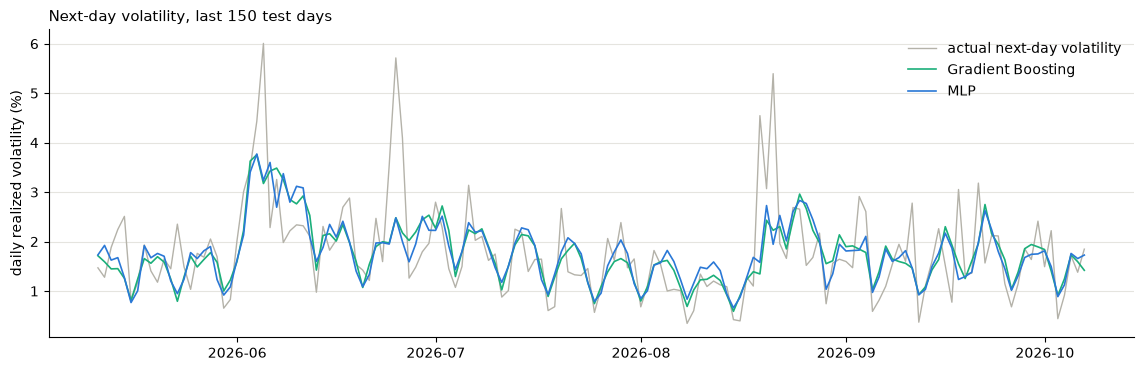

In [19]:
DV_COLS = BASE + B4 + NEXT_DAY_FEATURES                              # base + B4 + release in the next 24 hours
XW_tv, XW_te = Xw("tv", DV_COLS), Xw("test", DV_COLS)[test_days]
yd_tv, yd_te = U.day_log_vol(Ytv), U.day_log_vol(Yte[test_days])
lr_h = np.log1p(ret / U.PCT) * U.PCT                                 # hourly log returns, %
p_days = P["test"][test_days]
NAIVE_DV = "Baseline: last week's average volatility"
dv_test = {NAIVE_DV: np.log(np.sqrt(np.array([(lr_h[p - 167: p + 1] ** 2).sum() / 7 for p in p_days])) + 1e-6)}


def wf_folds(gs):
    # walk-forward scores of the chosen setting: mean, std and each fold
    f = [gs.cv_results_[f"split{i}_test_score"][gs.best_index_] for i in range(len(WF))]
    return {"WF R2": np.mean(f), "WF std": np.std(f, ddof=1), **{f"fold{i + 1}": s for i, s in enumerate(f)}}


GB_DV_GRID = {"learning_rate": [0.05, 0.1], "max_depth": [2, 3], "min_samples_leaf": [20, 100], "max_iter": [50, 100, 200]}
gb_dv_base = GridSearchCV(HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
                          GB_DV_GRID, cv=WF, scoring="r2", n_jobs=N_JOBS).fit(Ftv, yd_tv)
gb_dv = GridSearchCV(HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
                     GB_DV_GRID, cv=WF, scoring="r2", n_jobs=N_JOBS).fit(XW_tv, yd_tv)
MLP_DV_GRID = {"mlpregressor__hidden_layer_sizes": [(16,), (64, 32)], "mlpregressor__alpha": [0.1, 1.0, 10.0, 100.0],
               "mlpregressor__max_iter": [25, 50, 100, 200, 400, 800]}
mlp_dv = GridSearchCV(make_pipeline(StandardScaler(), MLPRegressor(early_stopping=False, random_state=RANDOM_STATE)),
                      MLP_DV_GRID, cv=WF, scoring="r2", n_jobs=N_JOBS).fit(XW_tv, yd_tv)
GB_DV_BASE = f"Classical: Gradient Boosting, base only {gb_dv_base.best_params_}"
GB_DV = f"Classical: Gradient Boosting {gb_dv.best_params_}"
MLP_DV = f"MLP {({k.split('__')[1]: v for k, v in mlp_dv.best_params_.items()})}"
print("MLP: walk-forward R2 against the number of epochs, for the chosen size and penalty")
cv = pd.DataFrame(mlp_dv.cv_results_)
same = np.all([cv[f"param_{k}"].map(str) == str(v) for k, v in mlp_dv.best_params_.items() if not k.endswith("max_iter")], axis=0)
display(cv[same].set_index("param_mlpregressor__max_iter")[["mean_test_score", "std_test_score"]].T.round(4))

dv_wf = {GB_DV_BASE: wf_folds(gb_dv_base), GB_DV: wf_folds(gb_dv), MLP_DV: wf_folds(mlp_dv)}
fold_pred = {k: [clone(gs.best_estimator_).fit(XW_tv[a], yd_tv[a]).predict(XW_tv[b]) for a, b in WF] for k, gs in [(GB_DV, gb_dv), (MLP_DV, mlp_dv)]}
ENS_DV = "Ensemble: GB + MLP"
f = [U.r2(yd_tv[b], (fold_pred[GB_DV][i] + fold_pred[MLP_DV][i]) / 2) for i, (_, b) in enumerate(WF)]
dv_wf[ENS_DV] = {"WF R2": np.mean(f), "WF std": np.std(f, ddof=1), **{f"fold{i + 1}": s for i, s in enumerate(f)}}

dv_seeds = {MLP_DV: [clone(mlp_dv.best_estimator_).set_params(mlpregressor__random_state=RANDOM_STATE + s).fit(XW_tv, yd_tv).predict(XW_te)
                     for s in range(N_SEEDS)]}
dv_test.update({GB_DV_BASE: gb_dv_base.predict(Fte[test_days]), GB_DV: gb_dv.predict(XW_te), MLP_DV: np.mean(dv_seeds[MLP_DV], axis=0)})
dv_test[ENS_DV] = (dv_test[GB_DV] + dv_test[MLP_DV]) / 2
dv_tab = pd.DataFrame.from_dict({k: {**dv_wf.get(k, {}), "test R2": U.r2(yd_te, v), "test MAE": mean_absolute_error(yd_te, v),
                                      "test corr": safe_corr(v, yd_te),
                                      "test R2, single seeds": seed_spread(yd_te, dv_seeds[k], U.r2) if k in dv_seeds else ""}
                                  for k, v in dv_test.items()}, orient="index")
display(dv_tab.round(4))
DV_CHOSEN = max([MLP_DV, ENS_DV], key=lambda k: dv_wf[k]["WF R2"])

fig, ax = plt.subplots(figsize=(14, 4))
last = slice(-150, None)
ax.plot(D["test"][test_days][last], np.exp(yd_te[last]), color=GREY, lw=1, label="actual next-day volatility")
ax.plot(D["test"][test_days][last], np.exp(dv_test[GB_DV][last]), color=AQUA, lw=1.2, label="Gradient Boosting")
ax.plot(D["test"][test_days][last], np.exp(dv_test[MLP_DV][last]), color=BLUE, lw=1.2, label="MLP")
ax.set_ylabel("daily realized volatility (%)")
ax.legend(frameon=False)
tidy(ax, "Next-day volatility, last 150 test days")
plt.show()

SUMMARY.append({"question": "next-day volatility", "network (chosen without the test)": f"{DV_CHOSEN} (best walk-forward R2 of MLP / ensemble)",
                "test result": f"R2 {U.r2(yd_te, dv_test[DV_CHOSEN]):.3f} (MLP alone {U.r2(yd_te, dv_test[MLP_DV]):.3f})",
                "classical reference (refitted here)": f"GB: R2 {U.r2(yd_te, dv_test[GB_DV]):.3f} (base only {U.r2(yd_te, dv_test[GB_DV_BASE]):.3f}); "
                                                       f"last week's average {U.r2(yd_te, dv_test[NAIVE_DV]):.3f}"})

### 6.1 What we see

**Answer: the MLP alone ties Gradient Boosting; averaged with it, it is reliably better: R² 0.518 against 0.505.**

- **The ensemble GB + MLP** has the best walk-forward R² (0.356, against 0.350 for Gradient Boosting; better on 3 of the 4 folds) and is chosen. On test it has **0.518**: +0.013 over Gradient Boosting, interval [+0.002, +0.024], better in 98.6% of the resamples (section 8). It is also above the top-3 tree ensemble of `classical-models.ipynb` (0.510), but that difference is not tested.
- **MLP vs. Gradient Boosting.** The chosen MLP (64, 32), alpha 1, 50 epochs, is below Gradient Boosting on the folds (0.286 against 0.350, with twice the spread: ±0.15 against ±0.08) but ties it on test (0.507 against 0.505; +0.002, interval [−0.021, +0.024]). Single seeds spread by ±0.010.
- **Number of epochs.** With data from 2020 the walk-forward R² peaks at 50 epochs (0.286) and then falls: 0.258 (100), 0.245 (200), 0.236 (400 and 800). The longer grid shows that the rise up to 200 epochs of the previous run (data from 2018) does not continue here.
- **The new inputs change nothing.** Gradient Boosting has walk-forward R² 0.350 with and without B4 and the releases of the next day, and on test it is slightly better without them (0.511 against 0.505). This is the result of `classical-models.ipynb` (section 8.4).

**Archived runs:** no archived notebook trained a network on this target. *(`bitcoin-models-v3.ipynb`, section 11)* "The fold-to-fold spread is large: the volatility R² changes by ±0.035–0.043 between periods. Any difference smaller than that, on a single block, cannot be trusted."

## 7. The course-lab MLP

**Question.** How large will tomorrow's moves be on average? The target, `size_next`, is the average |hourly change| of the next 24 hours, forecast once a day at 23:00.

**To beat.** Linear Regression, with SVR the best model of `classical-models.ipynb` (section 9): test R² 0.514.

**Network.** The small Keras MLP of `course-methods.ipynb` (Filip, section 6): "two hidden ReLU layers and one linear output neuron, trained with MSE. The last 20 % of the training days (in time order) are the validation set, and **early stopping** (Lab VI, Part XI) stops training when the validation loss stops improving."

**Inputs.** The 9 course attributes (`ret_1d`, `ret_7d`, `size_1d`, `vol_1d`, `vol_7d`, `range_1d`, `volume_ratio`, `last_hour`, `weekday`) through the course preprocessing pipeline. The fit days are the days of train + validation and the test days are those of the test block, as in `classical-models.ipynb` (section 9).

**Different from the other networks.** The Keras code is the original of `course-methods.ipynb`; only the variable names are mapped to those of this notebook (`train` → `fit_days`, `X_train` → `X_fit`, `X_test` → `X_test_c`, `y_train_size` → `y_fit_size`). As there, the network trained on the first 80% of the fit days and early-stopped on the last 20% is used directly on the test days, with one seed (42). It is not refitted on all fit days and not averaged over seeds.

### 7.1 Course attributes and the classical reference

The 9 attributes and the target at 23:00 of each day, the course preprocessing pipeline (median imputation and standardization for the numbers, one-hot encoding for the weekday), and the two references: "same as today" and Linear Regression.

In [20]:
r_h, close, volume = hourly["Return"], hourly["Close"], hourly["Volume"].clip(lower=0)
attributes = pd.DataFrame({
    "ret_1d": (close / close.shift(24) - 1) * 100,
    "ret_7d": (close / close.shift(168) - 1) * 100,
    "size_1d": r_h.abs().rolling(24).mean(),
    "vol_1d": r_h.rolling(24).std(),
    "vol_7d": r_h.rolling(168).std(),
    "range_1d": (hourly["High"].rolling(24).max() / hourly["Low"].rolling(24).min() - 1) * 100,
    "volume_ratio": np.log1p(volume.rolling(24).mean()) - np.log1p(volume.rolling(168).mean()),
    "last_hour": r_h,
    "weekday": (hourly.index + pd.Timedelta(hours=1)).day_name(),
})
attributes["size_next"] = r_h.abs().rolling(24).mean().shift(-24)    # average |hourly change| of the next 24 h

days = attributes[attributes.index.hour == 23].dropna()               # one forecast per day, at 23:00
fit_days = days[days.index + pd.Timedelta(hours=24) < TEST_START]     # train + validation: the next 24 h end before the test
test_c = days[days.index >= TEST_START - pd.Timedelta(hours=1)]
assert len(test_c) == ND and (test_c.index == D["test"][test_days]).all()   # the independent test days of section 1.2
num_cols = ["ret_1d", "ret_7d", "size_1d", "vol_1d", "vol_7d", "range_1d", "volume_ratio", "last_hour"]
cat_cols = ["weekday"]
X_fit, X_test_c = fit_days[num_cols + cat_cols], test_c[num_cols + cat_cols]
y_fit_size, y_test_size = fit_days["size_next"], test_c["size_next"]
print(f"fit:  {len(fit_days)} days {fit_days.index[0].date()} -> {fit_days.index[-1].date()}")
print(f"test: {len(test_c)} days {test_c.index[0].date()} -> {test_c.index[-1].date()}")

preprocessing = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])


def make_pipe(model):
    # A fresh copy of the preprocessing followed by the model, so models never share fitted steps
    return Pipeline([("prep", clone(preprocessing)), ("model", model)])


size_preds = {"Same as today (baseline)": X_test_c["size_1d"].values,
              "Classical: Linear Regression": make_pipe(LinearRegression()).fit(X_fit, y_fit_size).predict(X_test_c)}

fit:  1635 days 2020-01-08 -> 2024-06-29
test: 829 days 2024-06-30 -> 2026-10-06


### 7.2 The Keras MLP

The original code of `course-methods.ipynb`, then its training curve.

In [21]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from tensorflow import keras

keras.utils.set_random_seed(42)

n_valid = int(len(fit_days) * 0.2)
nn_prep = clone(preprocessing)
X_tr_nn = nn_prep.fit_transform(X_fit.iloc[:-n_valid])
X_va_nn = nn_prep.transform(X_fit.iloc[-n_valid:])
X_te_nn = nn_prep.transform(X_test_c)
y_tr_nn, y_va_nn = y_fit_size.iloc[:-n_valid], y_fit_size.iloc[-n_valid:]

mlp = keras.models.Sequential([
    keras.layers.Input(shape=X_tr_nn.shape[1:]),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1),
])
mlp.compile(loss="mse", optimizer=keras.optimizers.SGD(learning_rate=0.01))

early_stopping = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
history = mlp.fit(X_tr_nn, y_tr_nn, epochs=500, validation_data=(X_va_nn, y_va_nn),
                  callbacks=[early_stopping], verbose=0)

mlp_pred = mlp.predict(X_te_nn, verbose=0).ravel()
print("Epochs run:", len(history.history["loss"]), "| best epoch:", int(np.argmin(history.history["val_loss"])) + 1)
print("MLP test RMSE:", round(np.sqrt(mean_squared_error(y_test_size, mlp_pred)), 4),
      "| R2:", round(r2_score(y_test_size, mlp_pred), 4))

Epochs run: 209 | best epoch: 189
MLP test RMSE: 0.1257 | R2: 0.3993


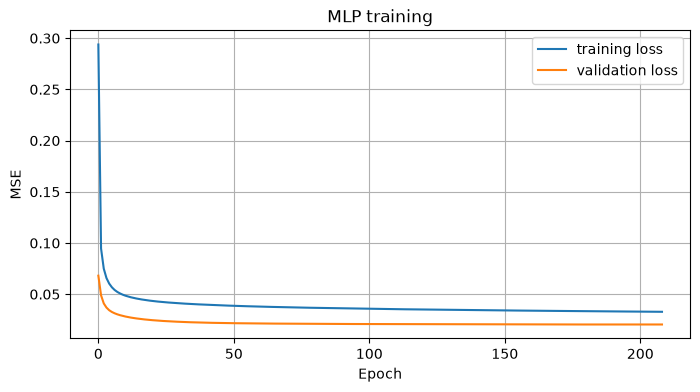

In [22]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MLP training")
plt.legend()
plt.grid(True)
plt.show()

### 7.3 Comparison on the test days

All models on the test days, next to the classical reference:

,RMSE,MAE,R2
Same as today (baseline),0.1624,0.1190,-0.0019
Classical: Linear Regression,0.1131,0.0820,0.5142
MLP (Keras),0.1257,0.0932,0.3993


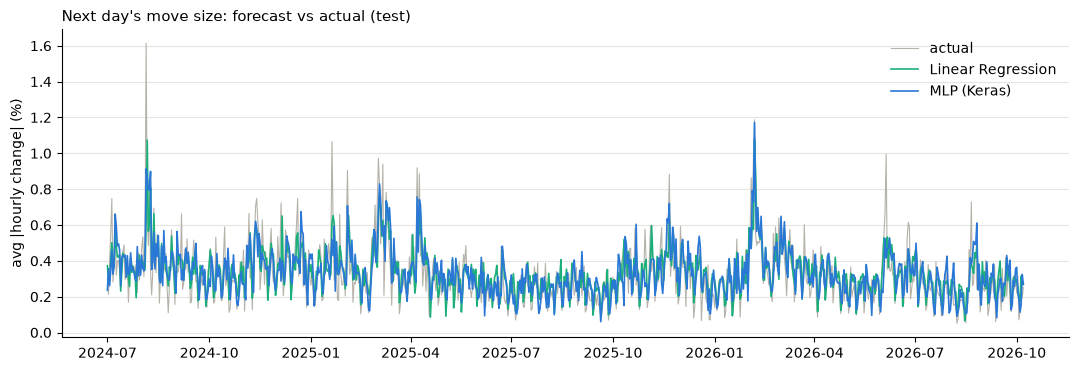

In [23]:
MLP_KERAS = "MLP (Keras)"
size_preds[MLP_KERAS] = mlp_pred
size_tab = pd.DataFrame({k: {"RMSE": np.sqrt(mean_squared_error(y_test_size, v)), "MAE": mean_absolute_error(y_test_size, v),
                             "R2": r2_score(y_test_size, v)} for k, v in size_preds.items()}).T
display(size_tab.round(4))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test_c.index, y_test_size, lw=0.8, color=GREY, label="actual")
ax.plot(test_c.index, size_preds["Classical: Linear Regression"], lw=1.2, color=AQUA, label="Linear Regression")
ax.plot(test_c.index, mlp_pred, lw=1.2, color=BLUE, label="MLP (Keras)")
ax.set_ylabel("avg |hourly change| (%)")
ax.legend(frameon=False)
tidy(ax, "Next day's move size: forecast vs actual (test)")
plt.show()

SUMMARY.append({"question": "next-day move size (course pipeline)", "network (chosen without the test)": "Keras MLP (32, 16) of course-methods",
                "test result": f"R2 {size_tab.loc[MLP_KERAS, 'R2']:.3f}",
                "classical reference (refitted here)": f"Linear Regression: R2 {size_tab.loc['Classical: Linear Regression', 'R2']:.3f}"})

### 7.4 What we see

**Answer: the MLP is still clearly behind Linear Regression: R² 0.399 against 0.514.**

- On the common blocks (fit days 2020-01-08 → 2024-06-29, 1,635 days; test days 2024-06-30 → 2026-10-06, 829 days), early stopping ran 209 epochs and restored the weights of epoch 189.
- The MLP has test R² **0.399** (RMSE 0.126), about the archived 0.37 and the 0.396 of the run from 2018. Linear Regression has R² 0.514 (RMSE 0.113). The difference, −0.115, is reliable: interval [−0.209, −0.034] (section 8).
- The archived explanation still holds: with about 1,600 fit days and a nearly linear relationship, the network has nothing extra to learn.
- This result comes from one seed and is not refitted on all fit days, unlike the other networks of this notebook.

**Archived run** *(`course-methods.ipynb`, section 6, train 2018–2023, test 2024 → Oct 2026)*

- "**Training:** Early stopping ended after 148 epochs and restored the weights from epoch 128, where the validation loss was lowest. The validation loss is lower than the training loss the whole time. This is not a mistake: the validation days (Oct 2022 – Dec 2023) were much calmer than the earlier training days (average move size 0.27 % vs 0.50 %), so their errors are smaller."
- "**Test set:** RMSE 0.133, **R² = 0.37**. That is clearly useful (much better than the baselines), but **worse than the simple Linear Regression** (0.48)."
- "**Why:** with about 1,750 training days and a relationship that is nearly linear, the network has nothing extra to learn and more parameters that can fit noise. Neural networks pay off with large amounts of data and complex patterns (images in Lab VI), not with a small table of 15 columns."

## 8. How sure are we? Bootstrap confidence intervals

*Method from `bitcoin-models-v3.ipynb`, section 14, as in `classical-models.ipynb`, section 11.*

A single test block gives a single number, which would change with a different sample of days. The **moving-block bootstrap** measures how much:

1. the 829 test days are resampled in blocks of 10 consecutive days (blocks keep the volatility clustering intact), 1,000 times;
2. the statistic is recomputed on each resample;
3. the 2.5% and 97.5% percentiles give a 95% interval.

For a **difference** between two models, computed on the same resampled days, an interval that does not include 0 means the difference is reliable.

For the hourly targets, a resampled day brings all 24 test origins of that day. Every network or ensemble below is the one chosen without the test, compared with the classical reference refitted in this notebook. For the size of the hourly moves there are two references: Gradient Boosting fitted once and Gradient Boosting refitted every month (section 5.1).

In [24]:
def day_orig(idx):
    # all test origins of the chosen independent days (the last day may be incomplete)
    o = (test_days[idx][:, None] + np.arange(24)).ravel()
    return o[o < len(P["test"])]


days_rows = lambda idx: rows24(day_orig(idx))                        # their 24 long-format rows each
r2_days = lambda pred, i: U.r2(ya["test"][days_rows(i)], pred[days_rows(i)])
auc_days = lambda score, i: roc_auc_score(y1["test"][day_orig(i)] > 0, score[day_orig(i)])
ret_chosen = test_preds[RET_CHOSEN]
boot_stats = {
    f"24 hourly returns R²_oos, {RET_CHOSEN}": lambda i: U.r2_oos(Yte[day_orig(i)], ret_chosen[day_orig(i)]),
    f"24 hourly returns IC, {RET_CHOSEN}": lambda i: safe_corr(ret_chosen[day_orig(i)], Yte[day_orig(i)]),
    f"next-hour AUC, {DIR_CHOSEN.split(' {')[0]} − GB": lambda i: auc_days(dir_scores[DIR_CHOSEN], i) - auc_days(dir_scores[GB_DIR], i),
    f"hourly |r| R², {ABS_CHOSEN}": lambda i: r2_days(abs_test[ABS_CHOSEN], i),
    f"hourly |r| R², {ABS_CHOSEN} − GB fitted once": lambda i: r2_days(abs_test[ABS_CHOSEN], i) - r2_days(abs_test[GB_ABS], i),
    f"hourly |r| R², {ABS_CHOSEN} − GB refitted monthly": lambda i: r2_days(abs_test[ABS_CHOSEN], i) - r2_days(abs_test[GB_REFIT], i),
    "hourly |r| R², GB refitted monthly − GB fitted once": lambda i: r2_days(abs_test[GB_REFIT], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², MLP − GB fitted once": lambda i: r2_days(abs_test[MLP_ABS], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², MLP refitted monthly − GB refitted monthly": lambda i: r2_days(abs_test[MLP_REFIT], i) - r2_days(abs_test[GB_REFIT], i),
    f"hourly |r| R², {LSTM_WIN.split(' {')[0]} − GB fitted once": lambda i: r2_days(abs_test[LSTM_WIN], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², LSTM + hour features − LSTM": lambda i: r2_days(abs_test[LSTM_FUT], i) - r2_days(abs_test[LSTM_ABS], i),
    "next-day vol R², MLP − GB": lambda i: U.r2(yd_te[i], dv_test[MLP_DV][i]) - U.r2(yd_te[i], dv_test[GB_DV][i]),
    "next-day vol R², ensemble GB + MLP − GB": lambda i: U.r2(yd_te[i], dv_test[ENS_DV][i]) - U.r2(yd_te[i], dv_test[GB_DV][i]),
    "next-day move size R², MLP (Keras) − Linear Regression": lambda i: r2_score(y_test_size.values[i], mlp_pred[i])
                                                                       - r2_score(y_test_size.values[i], size_preds["Classical: Linear Regression"][i]),
}
boot_rows = {}
for name, fn in boot_stats.items():
    b = U.block_bootstrap(fn, ND, n_boot=1000, block=10, seed=RANDOM_STATE)
    boot_rows[name] = {"estimate": fn(np.arange(ND)), "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5),
                       "share of resamples > 0": (b > 0).mean()}
with pd.option_context("display.max_colwidth", 90):
    display(pd.DataFrame(boot_rows).T.round(4))

,estimate,CI 2.5%,CI 97.5%,share of resamples > 0
"24 hourly returns R²_oos, LSTM, Huber loss",-0.0006,-0.0012,0.0000,0.035
"24 hourly returns IC, LSTM, Huber loss",0.0036,-0.0005,0.0075,0.966
"next-hour AUC, LSTM classifier, every origin (13 epochs) − GB",0.0051,-0.0013,0.0119,0.940
"hourly |r| R², LSTM + hour features {'hidden_size': 128}, every origin",0.1322,0.1110,0.1554,1.000
"hourly |r| R², LSTM + hour features {'hidden_size': 128}, every origin − GB fitted once",0.0027,-0.0062,0.0104,0.753
"hourly |r| R², LSTM + hour features {'hidden_size': 128}, every origin − GB refitted monthly",-0.0157,-0.0247,-0.0076,0.000
"hourly |r| R², GB refitted monthly − GB fitted once",0.0184,0.0119,0.0254,1.000
"hourly |r| R², MLP − GB fitted once",0.0019,-0.0045,0.0094,0.712
"hourly |r| R², MLP refitted monthly − GB refitted monthly",-0.0029,-0.0076,0.0023,0.131
"hourly |r| R², LSTM + hour features − GB fitted once",0.0022,-0.0067,0.0098,0.710


### 8.1 What the intervals say

As in `classical-models.ipynb`, a difference between two models measured on the same resampled days is much tighter than the level of either model. The R² of the chosen \|r\| network ranges over [0.111, 0.155] depending on the days, but its gap to the refitted Gradient Boosting stays inside [−0.025, −0.008].

| Question | Difference with the classical reference | Reliable? |
|---|---|---|
| 24 hourly returns | LSTM, Huber loss: R²_oos −0.0006 [−0.0012, +0.0000], IC +0.004 [−0.0005, +0.0075] | no: both intervals include 0, the zero forecast is not beaten |
| Next-hour direction | LSTM on every origin − GB: AUC +0.005 [−0.001, +0.012] | no: a tie (LSTM ahead in 94% of the resamples) |
| Size of each hourly move | LSTM + hour features on every origin − GB refitted monthly: R² **−0.016** [−0.025, −0.008] | **yes, the network is worse** than the best classical model |
| | the same − GB fitted once: +0.003 [−0.006, +0.010] | no: a tie |
| | GB refitted monthly − GB fitted once: +0.018 [+0.012, +0.025] | yes: the monthly refit helps |
| | MLP − GB fitted once: +0.002 [−0.005, +0.009] | no: a tie |
| | MLP refitted monthly − GB refitted monthly: −0.003 [−0.008, +0.002] | no: a tie |
| | LSTM + hour features − GB fitted once: +0.002 [−0.007, +0.010] | no: a tie |
| | LSTM + hour features − LSTM: **+0.034** [+0.027, +0.041] | **yes**: the features of the predicted hours help the LSTM |
| Next-day volatility | MLP − GB: +0.002 [−0.021, +0.024] | no: a tie |
| | ensemble GB + MLP − GB: **+0.013** [+0.002, +0.024] | **yes**, better in 98.6% of the resamples |
| Next-day move size | Keras MLP − Linear Regression: −0.115 [−0.209, −0.034] | yes, the MLP is worse |

A network or ensemble chosen without the test is reliably better than its classical reference in one interval (the next-day volatility ensemble) and reliably worse in two (the \|r\| network against the refitted Gradient Boosting, and the Keras MLP).

## 9. Conclusions

### 9.1 This run

The main test result of each section, every network chosen without looking at the test block, next to the classical reference refitted in this notebook:

In [25]:
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(SUMMARY).set_index("question"))
print(f"Total run time: {(time.time() - T_START) / 60:.1f} minutes")

,network (chosen without the test),test result,classical reference (refitted here)
question,,,
24 hourly returns,"LSTM, Huber loss (of MLP, RNN / LSTM with MSE / Huber)","MAE skill -0.0006 (all networks -0.0020 to -0.0004), IC +0.004",Ridge: MAE skill -0.0003
direction of the next hour,"LSTM classifier, every origin (13 epochs) (best validation AUC)","AUC 0.538, top 10% right 59.4% (p = 2e-17)",GB AUC 0.533; reversal rule 0.528
size of each of the next 24 hours (|r|),"LSTM + hour features {'hidden_size': 128}, every origin (best validation R2)","R2 0.132 (MLP 0.131, MLP refit 0.145, LSTM 0.132)",GB refitted monthly: R2 0.148; fitted once 0.130
next-day volatility,Ensemble: GB + MLP (best walk-forward R2 of MLP / ensemble),R2 0.518 (MLP alone 0.507),GB: R2 0.505 (base only 0.511); last week's average 0.094
next-day move size (course pipeline),"Keras MLP (32, 16) of course-methods",R2 0.399,Linear Regression: R2 0.514


Total run time: 41.2 minutes


### 9.2 Conclusions

1. **The assigned task stays at the zero forecast** (section 3). With window-normalized inputs and the Huber loss, the RNN and the LSTM still end at "no change": MAE skill −0.0020 to −0.0004, IC ≤ 0.005, about 50% daily direction. The Huber loss helps the RNN a little and the LSTM hardly at all; the best network (LSTM, Huber) stays just below Ridge and the mean per hour (−0.0003). The MLP repeats the pattern of versions 1–2: the more freedom it gets, the worse it does on validation (down to −0.050 at alpha 0.01). The README's fixes were right about the inputs and the loss, but a cause was missing: the target has no signal for any model.
2. **Next-hour direction: more rows, not a network** (section 4). The LSTM trained on every origin has AUC 0.538 and 59.4% right on its confident calls, a tie with Gradient Boosting (+0.005, interval [−0.001, +0.012]); Gradient Boosting on every origin is better still (0.541). Trained on every 6th origin, the same LSTM is below the reversal rule (0.519 against 0.528). Only its confident calls look better (59.4% against 53.9–55.9%), and that is not tested here.
3. **Size of each hourly move: the networks tie Gradient Boosting fitted once, but not the refitted one** (section 5). The best classical model is Gradient Boosting refitted every month with a half-life of 12 months: R² **0.148**, +0.018 over fitting once. On the same rows the MLP ties Gradient Boosting, fitted once (0.131 against 0.130) and refitted every month (0.145 against 0.148). The LSTM on the raw week is worse (0.098), but **telling it the clock, the recent hour profile and the releases of each predicted hour** lifts it to 0.132 (+0.034, reliable), the largest gain of a network in this notebook and the model chosen on validation. On test it ties Gradient Boosting fitted once and is reliably worse than the refitted one (−0.016). Averages of Gradient Boosting and the networks are better on test (up to 0.157), but validation did not choose them, because the networks' validation R² is optimistic (early stopping on the same block).
4. **The new features of `data-analysis.ipynb` do not help the trees** (sections 5.1 and 6): `CHOSEN_SET` = base + B3, as in `classical-models.ipynb`, and B4 with the releases of the next day leave the next-day volatility unchanged. For the LSTM, the features of the predicted hours (clock, recent profile, B5) are what makes it competitive.
5. **Next-day volatility: the ensemble GB + MLP is reliably better** (section 6): test R² 0.518 against 0.505 for Gradient Boosting (+0.013, interval [+0.002, +0.024]). The MLP alone is worse on the walk-forward folds (0.286 against 0.350) but ties on test (0.507). With data from 2020 its best number of epochs is 50; 400 and 800 epochs are worse.
6. **The course MLP is still behind Linear Regression** (section 7): test R² 0.399 against 0.514 on the common blocks, interval [−0.209, −0.034]. With about 1,600 days and a nearly linear relationship the network has nothing extra to learn.
7. **The overall picture of `classical-models.ipynb` (section 12) does not change.** Where there is no signal (hourly returns) the networks find none. Where there is, a network alone ties or trails Gradient Boosting, and adds something as a second model family in an ensemble (reliably for next-day volatility). The large gains of the project remain those of the classical notebook: asking the questions the data can answer, the long format and monthly refits, which help the MLP as much as the trees. With a GPU the networks are no longer expensive (41 minutes for the whole notebook, most of it the refits of Gradient Boosting on the CPU), so cost is no longer the argument against them; their results are.

### 9.3 The archived conclusions, checked against this run

- *(README, overall picture)* "**Hourly Bitcoin returns are close to a random walk**: no model (linear, trees, KNN, SVM, MLP, RNN, LSTM) beats predicting 0% change, and more flexible models only overfit." → **Still holds** (section 3).
- *(`bitcoin-models-new-data.ipynb`, conclusion 3)* "*MLP:* weak regularization (alpha 0.01–1) overfits badly (validation skill down to −0.04); alpha = 100 brings it back near 0." *(`bitcoin-models-2018-2026.ipynb`, conclusion 3)* "*MLP:* weak penalties overfit (validation down to −0.037). From alpha = 1000 on the result does not change (plateau)." → **Still holds**: validation skill down to −0.050 at alpha 0.01, plateau at −0.0007 to −0.0008 from alpha 100 on.
- *(README, on `model_test.ipynb`)* "All four variants end up equal to the zero forecast (MSE ratio 1.000–1.002) with ~50% direction accuracy. The training loss barely moves from the first epoch. Two things may be holding them back: the inputs are global-scaled prices that lie outside the training range in the test period, and the MSE loss is dominated by the few extreme hours." → **The result still holds after both fixes**: with window-normalized inputs and the Huber loss the four variants still equal the zero forecast. The target, not the inputs, is what holds the networks back.
- *(`course-methods.ipynb`, conclusions)* "**Predictable.** The best model, plain **Linear Regression**, explains about half of the variation (test R² 0.48). SVR (0.46), Random Forest (0.41) and the Keras MLP (0.37) follow. [...] More complex models did not help, because the relationship is close to linear and there are only about 2,000 training days." → **Still holds**: MLP 0.399, Linear Regression 0.514.
- *(README, task 7, in its earlier wording)* "Rerun RNN/LSTM with the normalized windows [task 6], a robust loss (Huber or MAE), and the volatility / hourly-size targets, where versions 3 and `v3-extensions` found real signal. Compare with their tree models on the same test block, ideally with monthly refits too." → Done in sections 3 and 5, with monthly refits for the MLP (not for the LSTM, 9.4). On the hourly-size target the LSTM finds real signal (R² 0.098, and 0.132 with the features of the predicted hours) and ties the tree model fitted once, but not the tree model refitted every month.

### 9.4 Not done here

- **A fairer choice on validation.** Early stopping and the final comparison use the same validation block, so the networks' validation R² is optimistic (section 5.6). Early stopping on its own block (for example the last months of train) or walk-forward folds for the networks, as for the daily targets, would compare them with the monthly refits on equal terms.
- **Monthly refits of the LSTM:** fine-tuning each month, for a few epochs, the network of the month before. The MLP gains as much from the refit as Gradient Boosting (+0.014), and the LSTM with the features of the predicted hours ties Gradient Boosting fitted once, so this is the most promising next step.
- **A bootstrap for the ensembles not chosen**, such as GB + MLP refitted monthly + LSTM on every origin (test R² 0.157, the best of the notebook): a test result chosen after looking at the test is not a result.
- Monthly refits for the next-day volatility models (+0.015 for Gradient Boosting in `classical-models.ipynb`, section 8.4b); an LSTM for next-day volatility; quantile networks for the 80% ranges; other architectures (GRU, temporal convolutions, Transformers); the Binance attributes.
- The two inputs of `model_test.ipynb` (global scaler vs. raw prices): the base data has no global scaler, and section 1.4 explains why both were replaced.